In [1]:
import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
import logging
import torch
import hydra
import sys
from hydra import compose, initialize
from omegaconf import OmegaConf
import torch.nn.functional as F
from sklearn.decomposition import PCA
import objaverse

os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

# DINO
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


In [2]:
import objaverse

UID = "04ab56ff7f5044629e424a6fcb871b76"        # Polipetto
#UID =  "026dfb57bcb5406688a7b20dfbecc6c2"    # chiave
UID = "0292b47486774a538c0f891605c7bda1"    # Macchinina
#UID = "01ab7318c6f748569ee683ea13ba78c0"   # Chitarra
objects = objaverse.load_objects(
    uids=[UID],
    download_processes=1
)

GLB_PATH = objects[UID]
print(f"Oggetto scaricato in: {GLB_PATH}")

Oggetto scaricato in: /home/riccardop02/.objaverse/hf-objaverse-v1/glbs/000-047/0292b47486774a538c0f891605c7bda1.glb


In [3]:
loaded = trimesh.load(GLB_PATH)  # SENZA force="mesh", per ispezionare
if isinstance(loaded, trimesh.Scene):
    print("n. geometrie:", len(loaded.geometry))
    for name, geom in loaded.geometry.items():
        mat = getattr(geom.visual, "material", None)
        print(name, type(geom.visual), getattr(mat, "name", mat))

        

n. geometrie: 1
Object_0 <class 'trimesh.visual.texture.TextureVisuals'> material


# Create The model

In [4]:
# Utilities
import pyrender


def load_mesh(model_path: str) -> trimesh.Trimesh:
    loaded = trimesh.load(model_path, force="mesh")

    if isinstance(loaded, trimesh.Scene):
        if len(loaded.geometry) == 0:
            raise ValueError(f"Nessuna geometria trovata in: {model_path}")
        mesh = loaded.dump(concatenate=True)
    else:
        mesh = loaded

    if not isinstance(mesh, trimesh.Trimesh):
        raise TypeError(f"Tipo mesh non supportato dopo il caricamento: {type(mesh)}")

    return mesh



def sample_pointcloud_with_color(mesh: trimesh.Trimesh, n_points: int) -> np.ndarray:
    """
    Campiona n_points sulla superficie della mesh e assegna il colore
    interpolando la UV map sulla texture.
    Ritorna (n_points, 6): xyz grezzo + rgb in [0, 255].
    """
    # Campiona punti sulla superficie; face_idx dice da quale triangolo viene ogni punto
    points, face_idx = trimesh.sample.sample_surface(mesh, n_points)

    # Coordinate baricentriche di ogni punto rispetto al suo triangolo
    triangles = mesh.triangles[face_idx]              # (n_points, 3, 3)
    bary = trimesh.triangles.points_to_barycentric(triangles, points)  # (n_points, 3)

    # UV dei 3 vertici di ogni triangolo campionato
    uv_all = mesh.visual.uv                            # (N_vertices, 2)
    face_uv = uv_all[mesh.faces[face_idx]]              # (n_points, 3, 2)

    # Interpola la UV nel punto usando le coordinate baricentriche
    point_uv = np.einsum('ij,ijk->ik', bary, face_uv)   # (n_points, 2)

    # DEF
    def get_texture_image(material):
        # Caso PBRMaterial (tipico glTF/glb)
        if hasattr(material, "baseColorTexture") and material.baseColorTexture is not None:
            return np.array(material.baseColorTexture.convert("RGB"))
        # Caso SimpleMaterial (tipico obj)
        if hasattr(material, "image") and material.image is not None:
            return np.array(material.image.convert("RGB"))
        raise AttributeError(
            f"Materiale di tipo {type(material)} non ha una texture immagine valida "
            f"(né baseColorTexture né image)."
        )


    # Campiona la texture in quelle coordinate UV
    texture_img = get_texture_image(mesh.visual.material)
    tex_h, tex_w = texture_img.shape[:2]

    u_px = np.clip((point_uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
    v_px = np.clip(((1 - point_uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)

    colors = texture_img[v_px, u_px].astype(np.float32)  # (n_points, 3), in [0, 255]

    return np.concatenate([points, colors], axis=-1).astype(np.float32)  # (n_points, 6)


def normalize_pointcloud(pc: np.ndarray) -> np.ndarray:
    """
    pc: (N, 6) con xyz grezzo e rgb in [0, 255].
    Ritorna (N, 6) con xyz in sfera unitaria e rgb in [-1, 1], + centroid, scale.
    """
    xyz = pc[:, :3].copy()
    rgb = pc[:, 3:].copy()

    centroid = xyz.mean(axis=0, keepdims=True)
    xyz = xyz - centroid
    scale = np.max(np.linalg.norm(xyz, axis=1))
    if scale > 0:
        xyz = xyz / scale

    rgb = (rgb / 255.0 - 0.5) / 0.5

    return np.concatenate([xyz, rgb], axis=-1).astype(np.float32), centroid, scale

def compute_normalization(model_dir: str, n_points: int) -> tuple[np.ndarray, float]:
    """
    Ricalcola centroid/scale con LA STESSA logica dello script UNI3D (sample + normalize).
    """
    mesh = load_mesh(model_dir)
    pc = sample_pointcloud_with_color(mesh, n_points)
    _, centroid, scale = normalize_pointcloud(pc)
    return centroid.squeeze().astype(np.float32), np.float32(scale)

def render_views_systematic(
    render_mesh,
    centroid: np.ndarray,
    scale: float,
    image_size: int,
    n_views: int,
    renderer: pyrender.OffscreenRenderer,
    camera_dist_factor: float = 2.2,
    yfov_deg: float = 50.0,
):
    """
    Renderizza n_views viste deterministiche dell'oggetto (fronte, retro, lati,
    sopra, sotto, angoli...) usando SEMPRE un OffscreenRenderer di dimensione
    fissa (image_size, image_size): questo garantisce che ogni immagine abbia
    esattamente la stessa shape, eliminando il ValueError di np.stack.

    Le pose (R, t) restituite sono espresse nello spazio NORMALIZZATO (la stessa
    sfera unitaria usata per il point cloud), coerentemente con centroid/scale
    calcolati da compute_normalization. Il rendering vero e proprio invece avviene
    nello spazio "raw" della mesh (centroid + direzione*scale), perche' la mesh
    caricata da build_pyrender_mesh non e' normalizzata.
    """
    yfov = math.radians(yfov_deg)
    fy = (image_size / 2.0) / math.tan(yfov / 2.0)
    fx = fy
    cx = cy = image_size / 2.0
    K = np.array([[fx, 0.0, cx], [0.0, fy, cy], [0.0, 0.0, 1.0]], dtype=np.float32)

    view_dirs = generate_view_directions(n_views)
    assert len(view_dirs) == n_views

    scene = pyrender.Scene(bg_color=[0.0, 0.0, 0.0, 1.0], ambient_light=[0.35, 0.35, 0.35])
    mesh_node = scene.add(render_mesh)

    camera = pyrender.PerspectiveCamera(yfov=yfov, aspectRatio=1.0)
    cam_node = scene.add(camera, pose=np.eye(4))
    light = pyrender.PointLight(color=np.ones(3), intensity=2.0)
    light_node = scene.add(light, pose=np.eye(4))

    images, masks, poses = [], [], []
    try:
        for d in view_dirs:
            # --- pose nello spazio normalizzato (quella che salviamo) ---
            eye_n = d * camera_dist_factor
            target_n = np.zeros(3)
            pose_n = _look_at_pose(eye_n, target_n)
            R_n = pose_n[:3, :3].T
            t_n = -R_n @ eye_n

            # --- pose nello spazio "raw" della mesh (quella che usiamo per renderizzare) ---
            eye_world = centroid + eye_n * scale
            target_world = centroid
            pose_world = _look_at_pose(eye_world, target_world)

            scene.set_pose(cam_node, pose_world)
            scene.set_pose(light_node, pose_world)

            color, depth = renderer.render(scene)  # color: (image_size, image_size, 3) uint8, SEMPRE

            img = color.astype(np.float32) / 255.0
            img = np.transpose(img, (2, 0, 1))  # (3, H, W), come si aspetta encoder2d

            images.append(img)
            masks.append(depth > 0)
            poses.append(np.concatenate([R_n.reshape(-1), t_n.reshape(-1)]).astype(np.float32))
    finally:
        scene.remove_node(mesh_node)
        scene.remove_node(cam_node)
        scene.remove_node(light_node)

    return images, masks, K, poses

def build_pyrender_mesh(model_dir: str) -> pyrender.Mesh:
    mesh = load_mesh(model_dir)
    return pyrender.Mesh.from_trimesh(mesh, smooth=False)

def generate_view_directions(n_views: int) -> list[np.ndarray]:
    """
    Genera n_views direzioni di vista distribuite in modo uniforme sulla sfera.
    """
    dirs = []
    golden_angle = math.pi * (3.0 - math.sqrt(5.0))
    for i in range(n_views):
        y = 1.0 - (i / float(max(n_views - 1, 1))) * 2.0  # da +1 a -1
        radius = math.sqrt(max(0.0, 1.0 - y * y))
        theta = golden_angle * i
        x = math.cos(theta) * radius
        z = math.sin(theta) * radius
        dirs.append(np.array([x, y, z]))
    return dirs

def _look_at_pose(eye: np.ndarray, target: np.ndarray, up_hint=np.array([0.0, 1.0, 0.0])) -> np.ndarray:
    """Pose camera->mondo (4x4), convenzione OpenGL/pyrender: la camera guarda
    lungo -Z, +Y e' up, +X e' right."""
    eye = np.asarray(eye, dtype=np.float64)
    target = np.asarray(target, dtype=np.float64)
    forward = target - eye
    norm = np.linalg.norm(forward)
    forward = forward / norm if norm > 1e-8 else np.array([0.0, 0.0, -1.0])

    up = up_hint
    if abs(np.dot(forward, up)) > 0.99:  # viste dall'alto/basso: up degenere
        up = np.array([1.0, 0.0, 0.0])

    right = np.cross(forward, up)
    right = right / np.linalg.norm(right)
    true_up = np.cross(right, forward)

    pose = np.eye(4)
    pose[:3, 0] = right
    pose[:3, 1] = true_up
    pose[:3, 2] = -forward
    pose[:3, 3] = eye
    return pose

DINOV2_MEAN = (0.485, 0.456, 0.406)
DINOV2_STD = (0.229, 0.224, 0.225)

def process_single_object(
    model_dir: str,
    encoder2d,
    n_points: int = 8192,
    n_views: int = 30,
    image_size: int = 224,
    device: torch.device = None,
    dino_mean: torch.Tensor = None,
    dino_std: torch.Tensor = None,
):
    """
    Versione 'live' di process_model: nessun salvataggio su disco, nessuna
    dipendenza da hydra/cfg. Crea e distrugge il proprio OffscreenRenderer
    ad ogni chiamata (self-contained, comoda per uso interattivo/notebook).

    Ritorna:
        feats3d:  (n_views, P, D) numpy  -- feature DINOv2 per patch, per vista
        centers:  (n_views, 12)  numpy  -- R_n(9) + t_n(3) per vista, spazio normalizzato
        centroid: (3,) numpy
        scale:    float
    """
    if device is None:
        device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    if dino_mean is None:
        dino_mean = torch.tensor(DINOV2_MEAN).view(3, 1, 1).to(device)
    if dino_std is None:
        dino_std = torch.tensor(DINOV2_STD).view(3, 1, 1).to(device)

    renderer = pyrender.OffscreenRenderer(image_size, image_size)
    try:
        centroid, scale = compute_normalization(model_dir, n_points)
        render_mesh = build_pyrender_mesh(model_dir)

        images, masks, K, poses = render_views_systematic(
            render_mesh=render_mesh,
            centroid=centroid,
            scale=scale,
            image_size=image_size,
            n_views=n_views,
            renderer=renderer,
        )

        imgs_t = torch.from_numpy(np.stack(images)).float().to(device)  # (n_views, 3, H, W)
        imgs_t = (imgs_t - dino_mean) / dino_std

        with torch.no_grad():
            patch_tokens = encoder2d(imgs_t)   # (n_views, P, D) -- STESSO encoder2d del target

        feats3d = patch_tokens.cpu().numpy()
        centers = np.stack(poses)              # (n_views, 12)

        return feats3d, centers, centroid, scale
    finally:
        renderer.delete()

def _generate_rays(K, R, trans, centroid, scale, grid_size=16, patch_size=14):
        """
        Plucker rays, normalized by centroid and scale of the 3D model.
        """
        B = K.shape[0]
        device = K.device

        y = torch.arange(grid_size, device=device, dtype=torch.float32)
        x = torch.arange(grid_size, device=device, dtype=torch.float32)
        grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')

        u = grid_x * patch_size + (patch_size / 2.0)
        v = grid_y * patch_size + (patch_size / 2.0)

        uv1 = torch.stack([u, v, torch.ones_like(u)], dim=-1).reshape(-1, 3)
        uv1 = uv1.unsqueeze(0).expand(B, -1, -1)

        K_inv = torch.linalg.inv(K)
        d_c = torch.bmm(uv1, K_inv.transpose(1, 2))

        R_inv = R.transpose(1, 2)
        d_o = F.normalize(torch.bmm(d_c, R_inv.transpose(1, 2)), p=2, dim=-1)   # (B, N, 3)

       
        centroid_col = centroid.unsqueeze(-1)                                            # (B, 3, 1)
        trans_norm = (trans.unsqueeze(-1) + torch.bmm(R, centroid_col)).squeeze(-1)      # (B, 3)
        trans_norm = trans_norm / scale.unsqueeze(-1)                                    # (B, 3)

        O = -torch.bmm(R_inv, trans_norm.unsqueeze(-1)).squeeze(-1)                      # (B, 3)
        O_exp = O.unsqueeze(1).expand(-1, d_o.shape[1], -1)
        moment = torch.cross(O_exp, d_o, dim=-1)                                         # (B, N, 3)

        return d_o, moment

def masked_l1_per_sample(pred_tensor, targ_tensor, mask_tensor):
    """Restituisce la L1 mascherata per ogni elemento del batch: shape (B,)"""
    err = F.l1_loss(pred_tensor, targ_tensor, reduction='none').mean(dim=-1)  # (B, N)
    valid = mask_tensor.float()
    return (err * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)


In [5]:
# Instatiate the model

sys.path.insert(0, "/home/riccardop02/JEPA")

logging.basicConfig(level=logging.INFO)
log = logging.getLogger(__name__)

# --- Config ---
with initialize(version_base=None, config_path="../../configs"):
    cfg = compose(config_name="config")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Only for the UNI3D
cfg.encoder3d['ckpt_path'] = "/home/riccardop02/JEPA/weights/model.pt"

# --- Istanzia i modelli ---
encoder2d = hydra.utils.instantiate(cfg.encoder2d)
encoder3d = hydra.utils.instantiate(cfg.encoder3d)
encoder2d.to(device)
encoder3d.to(device)
log.info("Dino Initialized...")
log.info(f"Encoder2d: {type(encoder2d)}, output_dim: {encoder2d.output_dim}, "
          f"layers: {encoder2d.layers}, token: {encoder2d.token}")
log.info(f"Encoder3d: {type(encoder3d)}, output_dim: {encoder3d.output_dim}")

predictor = hydra.utils.instantiate(
    cfg.Predictor,
    context_dim=encoder3d.output_dim[0][-1],
    output_dim=encoder2d.output_dim[-1]
)
predictor.to(device)

# predictor appena inizializzato (pesi random), per confronto/test strutturale
predictor_init = hydra.utils.instantiate(
    cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder2d.output_dim[-1]
).to(device)
predictor_init.eval()

# --- Carica checkpoint ---
PATH_CHECK = '/experiments/riccardop02/outputs/2026-09-19/15-32-13/checkpoints/best.pt' 
checkpoint = torch.load(PATH_CHECK, map_location=device, weights_only=False)

encoder2d.load_state_dict(checkpoint["models"]['encoder2d'])
predictor.load_state_dict(checkpoint["models"]['predictor'])
#encoder3d.load_state_dict(checkpoint["models"]['encoder3d'])

encoder2d.eval()
predictor.eval()
#encoder3d.eval()
log.info(f"Checkpoint loaded from {PATH_CHECK}, epoch {checkpoint['epoch']}")




INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

INFO:root:Uni3D constructed, loading Uni3D weights from /home/riccardop02/JEPA/weights/model.pt ...
INFO:__main__:Dino Initialized...
INFO:__main__:Encoder2d: <class 'src.models.encoder2d.DINOv2.DINOv2'>, output_dim: torch.Size([256, 768]), layers: [9], token: PatchToken
INFO:__main__:Encoder3d: <class 'src.models.encoder3d.Uni3D.Uni3DEncoder'>, output_dim: ((1, 512, 768), (1, 512, 3))
INFO:root:RenderPredictor initialized (depth=6, expand_depth=2, grid=16x16, rot6d=True, no rays)
INFO:root:RenderPredictor initialized (depth=6, expand_depth=2, grid=16x16, rot6d=True, no rays)
INFO:__main__:Checkpoint loaded from /experiments/riccardop02/outputs/2026-09-19/15-32-13/checkpoints/best.pt, epoch 88


In [6]:
# compute feature of the object
import math
feats3d, centers, centroid, scale = process_single_object(GLB_PATH, encoder2d, n_points=8192, device=device)

log.info(f"3D features: {feats3d.shape}, centers: {centers.shape}")


INFO:__main__:3D features: (30, 256, 768), centers: (30, 12)


In [8]:
os.environ["PYOPENGL_PLATFORM"] = "egl"  # rendering offscreen headless
import pyrender

N_VIEW = 36
IMG_SIZE = 224
CAM_DIST = 5.0          # distanza in spazio NORMALIZZATO (quella con cui è stato allenato il modello)
FOV_Y = np.pi / 3.0

# --- Carica la mesh RAW, SENZA normalizzarla ---
scene_trimesh = trimesh.load(GLB_PATH, force="scene")
mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh
# NIENTE mesh_tm.vertices -= ... / *= ... qui: usiamo le coordinate raw,
# centroid/scale (calcolati sopra da process_single_object) faranno da convertitore

mesh = pyrender.Mesh.from_trimesh(mesh_tm, smooth=False)

# --- Distanza camera in unità RAW, coerente con lo `scale` del point cloud ---
CAM_DIST_RAW = CAM_DIST * scale

# --- Intrinseca (costante per tutte le viste) ---
def get_intrinsics(width, height, fov_y):
    f = height / (2 * np.tan(fov_y / 2))
    cx, cy = width / 2, height / 2
    return np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]], dtype=np.float32)

K = get_intrinsics(IMG_SIZE, IMG_SIZE, FOV_Y)

renderer = pyrender.OffscreenRenderer(IMG_SIZE, IMG_SIZE)
camera = pyrender.PerspectiveCamera(yfov=FOV_Y, aspectRatio=1.0)
light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)

# --- Look-at coerente con la convenzione di training (OpenCV: +Z forward, Y down) ---
def look_at_opencv(eye, target=np.array([0.0, 0.0, 0.0]), world_up=np.array([0.0, 1.0, 0.0])):
    """
    Ritorna:
      R_w2c : (3,3) rotazione world-to-camera, convenzione OpenCV
      t_w2c : (3,)  traslazione world-to-camera coerente con R_w2c
      cam_pose_gl : (4,4) posa camera-to-world in convenzione OpenGL, per pyrender
    """
    forward = target - eye
    forward = forward / np.linalg.norm(forward)

    right = np.cross(forward, world_up)
    right = right / np.linalg.norm(right)
    up = np.cross(right, forward)

    R_cam_to_world = np.stack([right, -up, forward], axis=1)
    R_w2c = R_cam_to_world.T
    t_w2c = -R_w2c @ eye

    cam_pose_gl = np.eye(4)
    cam_pose_gl[:3, :3] = R_cam_to_world
    cam_pose_gl[:3, 3] = eye
    cv_to_gl = np.diag([1.0, -1.0, -1.0, 1.0])
    cam_pose_gl = cam_pose_gl @ cv_to_gl

    return R_w2c.astype(np.float32), t_w2c.astype(np.float32), cam_pose_gl


# --- Dizionario principale: view_id -> {rgb, mask, K, R, ...} ---
render_data = {}

for i in range(N_VIEW):
    theta = 2 * np.pi * i / N_VIEW
    phi = np.pi / 4

    direction = np.array([
        np.cos(theta) * np.sin(phi),
        np.cos(phi),
        np.sin(theta) * np.sin(phi)
    ])
    eye = centroid + CAM_DIST_RAW * direction   # <-- orbita attorno al centroid, in unità raw

    R_pose, T_cam, cam_pose = look_at_opencv(eye, target=centroid)  # <-- guarda verso centroid

    scene = pyrender.Scene(bg_color=[0, 0, 0, 1.0], ambient_light=[0.3, 0.3, 0.3])
    scene.add(mesh)
    scene.add(camera, pose=cam_pose)
    scene.add(light, pose=cam_pose)

    color, depth = renderer.render(scene, flags=pyrender.RenderFlags.RGBA)

    render_data[i] = {
        "rgb": color[..., :3],
        "mask": (depth > 0).astype(np.uint8) * 255,
        "K": K,
        "R_pose": R_pose,
        "eye": eye,
        "T_cam": T_cam,
        "theta": theta,
        "phi": phi,
    }

renderer.delete()

print(f"Renderizzate {N_VIEW} viste, salvate in memoria in `render_data`.")

/tmp/ipykernel_88052/3776933210.py:11: DeprecationWarning: `Scene.dump(concatenate=True)` DEPRECATED FOR REMOVAL APRIL 2025: replace with `Scene.to_geometry()`
  mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh


Renderizzate 36 viste, salvate in memoria in `render_data`.





In [9]:
#Plotting each view and the mask
fig, axes = plt.subplots(N_VIEW, 2, figsize=(6, 3 * N_VIEW))

for i in range(N_VIEW):
    axes[i, 0].imshow(render_data[i]["rgb"])
    axes[i, 0].set_title(f"View {i} - RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(render_data[i]["mask"], cmap="gray")
    axes[i, 1].set_title(f"View {i} - Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [10]:
from PIL import Image as PILImage

GRID_SIZE = 16

def pixel_mask_to_token_mask(mask, grid_size=16):
    mask_pil = PILImage.fromarray((mask.astype(np.uint8)) * 255 if mask.max() <= 1 else mask.astype(np.uint8))
    mask_grid = mask_pil.resize((grid_size, grid_size), PILImage.BOX)
    return np.array(mask_grid, dtype=np.float32) / 255.0  # valori continui [0,1]

def to_rgb_map_local(pca_tokens, grid_size=GRID_SIZE):
    """Normalizzazione min/max LOCALE, calcolata solo sui token passati (come nello script di validation)."""
    vmin = pca_tokens.min(axis=0, keepdims=True)
    vmax = pca_tokens.max(axis=0, keepdims=True)
    norm = (pca_tokens - vmin) / (vmax - vmin + 1e-8)
    norm = np.clip(norm, 0, 1)
    return norm.reshape(grid_size, grid_size, 3)

def rotation_matrix(axis, deg, device):
    """Matrice di rotazione 3x3 attorno a un asse ('x', 'y' o 'z')."""
    rad = np.deg2rad(deg)
    c, s = np.cos(rad), np.sin(rad)
    if axis == 'x':
        R = np.array([[1, 0, 0],
                      [0, c, -s],
                      [0, s,  c]], dtype=np.float32)
    elif axis == 'y':
        R = np.array([[ c, 0, s],
                      [ 0, 1, 0],
                      [-s, 0, c]], dtype=np.float32)
    elif axis == 'z':
        R = np.array([[c, -s, 0],
                      [s,  c, 0],
                      [0,  0, 1]], dtype=np.float32)
    else:
        raise ValueError("axis deve essere 'x', 'y' o 'z'")
    return torch.from_numpy(R).to(device)


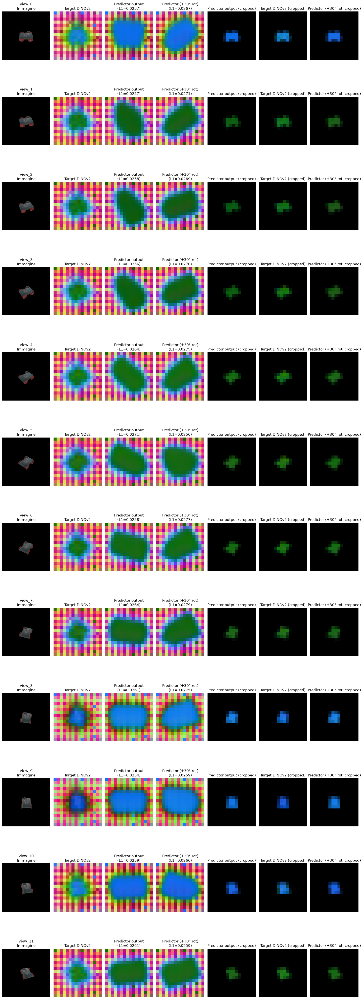

In [11]:
from sklearn.decomposition import PCA

N_OBJECTS = min(12, len(render_data))
GRID_SIZE = 16
WRONG_ROT_DEG = 30.0  # gradi di rotazione errata da aggiungere

MEAN_t = torch.tensor(MEAN, dtype=torch.float32, device=device).view(1, 3, 1, 1)
STD_t = torch.tensor(STD, dtype=torch.float32, device=device).view(1, 3, 1, 1)

context_dino = torch.from_numpy(feats3d).unsqueeze(0).to(device)
centers_t = torch.from_numpy(centers).unsqueeze(0).to(device)

            # (B, N, 12)
context_R = centers_t[..., :9].reshape(*centers_t.shape[:-1], 3, 3).to(device).float()  # (B, N, 3, 3)
context_t = centers_t[..., 9:].to(device).float()  # (B, N, 3)


R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # <-- cambia asse se serve

view_ids = list(render_data.keys())[:N_OBJECTS]

fig, axes = plt.subplots(N_OBJECTS, 7, figsize=(16.8, 4 * N_OBJECTS))
if N_OBJECTS == 1:
    axes = axes[None, :]

for i, vid in enumerate(view_ids):
    view = render_data[vid]

    img_np = view["rgb"].astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
    img_t = (img_t - MEAN_t) / STD_t

    mask_t = torch.from_numpy(view["mask"].astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(device)

    K_t = torch.from_numpy(view["K"]).unsqueeze(0).to(device).float()
    # R world-to-camera corretta: è R_pose, non R_cam (che è camera-to-world)
    rot_t = torch.from_numpy(view["R_pose"]).unsqueeze(0).to(device).float()
    trans_t = torch.from_numpy(view["T_cam"]).unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)
    token_mask_np = pixel_mask_to_token_mask(view["mask"], grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)
    

    mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)

    centroid_t = torch.from_numpy(centroid).unsqueeze(0).to(device).float()   # (1, 3)
    scale_t = torch.tensor([scale], device=device).float()      



    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(
            R_query=rot_t, t_query=trans_t,
                    context_dino=context_dino, context_R=context_R, context_t=context_t,
                    centroid=centroid_t, scale=scale_t
        )
        pred_wrong = predictor(
            R_query=rot_wrong_t, t_query=trans_t,
                    context_dino=context_dino, context_R=context_R, context_t=context_t,
                    centroid=centroid_t, scale=scale_t,
        )
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()


    target_np = target.squeeze(0).cpu().numpy()          # (256, 768)
    pred_np = pred.squeeze(0).cpu().numpy()               # (256, 768)
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()    # (256, 768)

    # --- PCA fittata SOLO sul target di QUESTA vista ---
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)  # stessa PCA del target, come richiesto

    # --- Normalizzazione min/max LOCALE ---
    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"view_{vid}\nImmagine")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_map)
    axes[i, 2].set_title(f"Predictor output\n(L1={l1_pred:.4f})")
    axes[i, 2].axis('off')

    axes[i, 3].imshow(pred_wrong_map)
    axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\n(L1={l1_pred_wrong:.4f})")
    axes[i, 3].axis('off')

    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 4].set_title("Predictor output (cropped)")
    axes[i, 4].axis('off')

    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 5].set_title("Target DINOv2 (cropped)")
    axes[i, 5].axis('off')


    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot, cropped)")
    axes[i, 6].axis('off')

plt.tight_layout()
plt.show();

In [12]:
# =========================
# Carica un batch dal dataset di validation (riusa il `cfg` già caricato in Cell 6)
# =========================
BATCH_SIZE = 40

dataset = hydra.utils.instantiate(cfg.data, dataset_source=cfg.gso.root, split="val")
loader_single = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, num_workers=0)
sample_iter = iter(loader_single)


INFO:src.data.Stream_Dataset:[val] RenderDatasetStreaming(wds, prefetch_depth=6): repo=Saiukk/POSEJEPA_Training, 103 modelli attesi, epoch=0


INFO:httpx:HTTP Request: GET https://huggingface.co/api/datasets/Saiukk/POSEJEPA_Training/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/datasets/Saiukk/POSEJEPA_Training/tree/main?expand=false&recursive=true&limit=1000&cursor=ZXlKbWFXeGxYMjVoYldVaU9pSmtZWFJoTDNSeVlXbHVMMlZ3YjJOb1h6QTBPUzl6YUdGeVpDMHdNREF4TlM1MFlYSWlMQ0owY21WbFgyOXBaQ0k2SWpWaE9EYzJOamd5WldVd056RTNOakExT1RRM09XRmpOall5WlRVM1pXVXdNV1l6WmpZMVpXVWlmUT09OjEwMDA%3D "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/datasets/Saiukk/POSEJEPA_Training/tree/main?expand=false&recursive=true&limit=1000&cursor=ZXlKbWFXeGxYMjVoYldVaU9pSmtZWFJoTDNaaGJDOWxjRzlqYUY4d01Ua3ZjMmhoY21RdE1EQXdNVEV1ZEdGeUlpd2lkSEpsWlY5dmFXUWlPaUkxWVRnM05qWTRNbVZsTURjeE56WXdOVGswTnpsaFl6WTJNbVUxTjJWbE1ERm1NMlkyTldWbEluMD06MjAwMA%3D%3D "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/datasets/Saiukk/POSEJEPA_Training/tree/main?expand=false&recursive

[download-start] worker=main data/val/epoch_000/shard-00000.tar @ 1789910171.85
[download-start] worker=main data/val/epoch_000/shard-00001.tar @ 1789910171.86
[download-start] worker=main data/val/epoch_000/shard-00002.tar @ 1789910171.86
[download-start] worker=main data/val/epoch_000/shard-00003.tar @ 1789910171.86
[download-start] worker=main data/val/epoch_000/shard-00004.tar @ 1789910171.86
[download-start] worker=main data/val/epoch_000/shard-00005.tar @ 1789910171.86


INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00001.tar "HTTP/1.1 302 Found"


[download] worker=main data/val/epoch_000/shard-00001.tar: 8.7MB in 0.14s (60.8 MB/s)


INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00005.tar "HTTP/1.1 302 Found"


[download] worker=main data/val/epoch_000/shard-00005.tar: 8.7MB in 0.15s (59.9 MB/s)


INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00000.tar "HTTP/1.1 302 Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00003.tar "HTTP/1.1 302 Found"


... (3 outputs left out)

INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00002.tar "HTTP/1.1 302 Found"


[download] worker=main data/val/epoch_000/shard-00003.tar: 8.6MB in 0.17s (51.3 MB/s)
[download] worker=main data/val/epoch_000/shard-00004.tar: 8.7MB in 0.17s (51.8 MB/s)
[download] worker=main data/val/epoch_000/shard-00002.tar: 8.8MB in 0.17s (51.4 MB/s)


/home/riccardop02/JEPA/src/data/Stream_Dataset.py:199: UserWarning: The given buffer is not writable, and PyTorch does not support non-writable tensors. This means you can write to the underlying (supposedly non-writable) buffer using the tensor. You may want to copy the buffer to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:1560.)
  img_tensor_uint8 = torch.frombuffer(image_bytes, dtype=torch.uint8)
INFO:httpx:HTTP Request: HEAD https://huggingface.co/datasets/Saiukk/POSEJEPA_Training/resolve/main/data/val/epoch_000/shard-00006.tar "HTTP/1.1 302 Found"


[download] worker=main data/val/epoch_000/shard-00006.tar: 8.8MB in 0.14s (61.3 MB/s)
Reebok_ZIGLITE_RUSH: L1 pred=0.0245 | L1 pred(+90°)=0.0324
Great_Jones_Wingtip: L1 pred=0.0239 | L1 pred(+90°)=0.0299
Wilton_Easy_Layers_Cake_Pan_Set: L1 pred=0.0228 | L1 pred(+90°)=0.0290
Just_For_Men_Mustache_Beard_Brushin_Hair_Color_Gel_MediumDark_Brown_M40: L1 pred=0.0220 | L1 pred(+90°)=0.0263
Little_Debbie_Donut_Sticks_6_cake_donuts_10_oz_total: L1 pred=0.0225 | L1 pred(+90°)=0.0290
Now_Designs_Snack_Bags_Bicycle_2_count: L1 pred=0.0240 | L1 pred(+90°)=0.0273
Reebok_FS_HI_INT_R12: L1 pred=0.0242 | L1 pred(+90°)=0.0315
Whey_Protein_3_Flavor_Variety_Pack_12_Packets: L1 pred=0.0234 | L1 pred(+90°)=0.0284


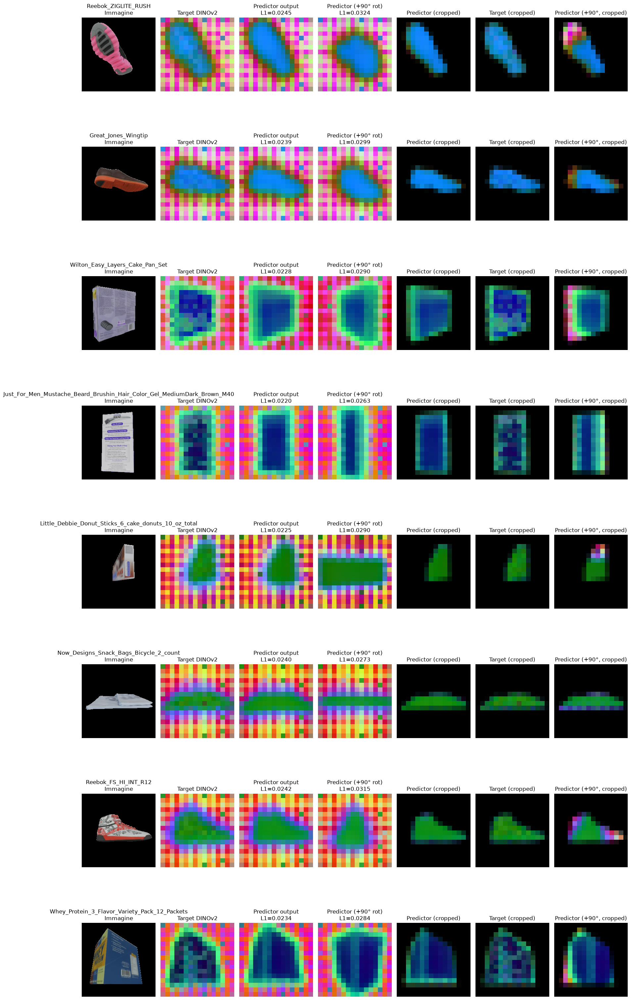

In [13]:
# =========================
# Visualizzazione target vs predictor su sample reali dal batch
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]


N_SHOW = min(8, actual_bs)
WRONG_ROT_DEG = 90.0
R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # riusa da Cell 9

fig, axes = plt.subplots(N_SHOW, 7, figsize=(16.8, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    img_i = batch['image'][i].unsqueeze(0).to(device).float()   # (1,3,H,W)
    mask_i = batch['mask'][i].to(device).float()                 # (H,W)

    # --- Auto-detect: immagine gia' normalizzata (mean/std) o raw [0,1]? ---
    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i  # gia' normalizzata dal dataset

    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()   # world-to-camera
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

    # --- context 3D e normalizzazione geometrica: gia' pronti dal dataset ---
    context_dino = batch['context_3d'][i].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].unsqueeze(0).to(device).float()
    scale_t = batch['scale'][i].unsqueeze(0).to(device).float()

    context_pose = batch["center_3d"][i].unsqueeze(0).to(device).float()                 # (B, N, 12)
    context_R = context_pose[..., :9].reshape(*context_pose.shape[:-1], 3, 3).to(device).float()  # (B, N, 3, 3)
    context_t = context_pose[..., 9:].to(device).float()  # (B, N, 3)

    # --- mask a livello di token (16x16) ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)  # da Cell 8
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()  # (1, N)

    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(
                    R_query=rot_t, t_query=trans_t,
                    context_dino=context_dino, context_R=context_R, context_t=context_t,
                    centroid=centroid_t, scale=scale_t,
                )
                          
        pred_wrong = predictor(R_query=rot_wrong_t, t_query=trans_t,
                            context_dino=context_dino, context_R=context_R, context_t=context_t,
                            centroid=centroid_t, scale=scale_t,
                        )

        # --- L1 mascherata (sull'embedding pieno, non sulla PCA) ---
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()

    target_np = target.squeeze(0).cpu().numpy()
    pred_np = pred.squeeze(0).cpu().numpy()
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)

    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    print(f"{model_name}: L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_pred_wrong:.4f}")

    axes[i, 0].imshow(bg_img); axes[i, 0].set_title(f"{model_name}\nImmagine"); axes[i, 0].axis('off')
    axes[i, 1].imshow(target_map); axes[i, 1].set_title("Target DINOv2"); axes[i, 1].axis('off')
    axes[i, 2].imshow(pred_map); axes[i, 2].set_title(f"Predictor output\nL1={l1_pred:.4f}"); axes[i, 2].axis('off')
    axes[i, 3].imshow(pred_wrong_map); axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\nL1={l1_pred_wrong:.4f}"); axes[i, 3].axis('off')
    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 4].set_title("Predictor (cropped)"); axes[i, 4].axis('off')
    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 5].set_title("Target (cropped)"); axes[i, 5].axis('off')
    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}°, cropped)"); axes[i, 6].axis('off')

plt.tight_layout()
plt.show()

In [14]:
import trimesh
import pyrender
import numpy as np
import os

_CV_TO_GL = np.array([
    [1,  0,  0, 0],
    [0, -1,  0, 0],
    [0,  0, -1, 0],
    [0,  0,  0, 1],
], dtype=np.float32)


def render_gso_object(model_name, R, t, K, img_size=(224, 224),
                       gso_root='/data/riccardop02/datasets/gso',
                       centroid=None, scale=None,
                       mesh_filename_candidates=('meshes/model.obj', 'model.obj',
                                                  'meshes/model.glb', 'model.glb')):

    # --- Trova e carica la mesh ---
    mesh_path = None
    for cand in mesh_filename_candidates:
        p = os.path.join(gso_root, model_name, cand)
        if os.path.exists(p):
            mesh_path = p
            break
    if mesh_path is None:
        raise FileNotFoundError(f"Mesh non trovata per {model_name} in {gso_root}")

    tm = trimesh.load(mesh_path, force='mesh')

    # --- Normalizzazione opzionale (centroid/scale), coerente con _generate_rays ---
    if centroid is not None and scale is not None:
        centroid = np.asarray(centroid, dtype=np.float32).reshape(3)
        tm.vertices = (tm.vertices - centroid) / scale

        # trans_norm = (t + R @ centroid) / scale   <- stessa identica formula dei raggi
        t_render = (t + R @ centroid) / scale
    else:
        t_render = t

    mesh = pyrender.Mesh.from_trimesh(tm, smooth=True)

    # --- Scena ---
    scene = pyrender.Scene(bg_color=[0, 0, 0, 0], ambient_light=[0.4, 0.4, 0.4])
    scene.add(mesh)

    light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)
    scene.add(light, pose=np.eye(4))

    fx, fy = K[0, 0], K[1, 1]
    cx, cy = K[0, 2], K[1, 2]
    camera = pyrender.IntrinsicsCamera(fx=fx, fy=fy, cx=cx, cy=cy, znear=0.01, zfar=100.0)

    extrinsic = np.eye(4, dtype=np.float32)
    extrinsic[:3, :3] = R
    extrinsic[:3, 3] = t_render

    cam_to_world_cv = np.linalg.inv(extrinsic)
    camera_pose = cam_to_world_cv @ _CV_TO_GL

    scene.add(camera, pose=camera_pose)

    r = pyrender.OffscreenRenderer(viewport_width=img_size[1], viewport_height=img_size[0])
    color, depth = r.render(scene)
    r.delete()

    return color

# TEST ROTATION (on Val)

Dino_4: | Vera posa L1=0.0251 | +2° L1=0.0250 | +5° L1=0.0249 | +10° L1=0.0249 | +25° L1=0.0253 | +50° L1=0.0264 | +90° L1=0.0288 | +150° L1=0.0265 | +180° L1=0.0262 | +360° L1=0.0251
Asus_Z87PRO_Motherboard_ATX_LGA1150_Socket: | Vera posa L1=0.0237 | +2° L1=0.0235 | +5° L1=0.0237 | +10° L1=0.0258 | +25° L1=0.0307 | +50° L1=0.0293 | +90° L1=0.0284 | +150° L1=0.0274 | +180° L1=0.0243 | +360° L1=0.0237
Santa_Cruz_Mens_umxTczr1Ygg: | Vera posa L1=0.0223 | +2° L1=0.0224 | +5° L1=0.0227 | +10° L1=0.0232 | +25° L1=0.0274 | +50° L1=0.0318 | +90° L1=0.0318 | +150° L1=0.0320 | +180° L1=0.0289 | +360° L1=0.0223
ZigKick_Hoops: | Vera posa L1=0.0233 | +2° L1=0.0233 | +5° L1=0.0231 | +10° L1=0.0228 | +25° L1=0.0251 | +50° L1=0.0291 | +90° L1=0.0302 | +150° L1=0.0302 | +180° L1=0.0293 | +360° L1=0.0233
Womens_Teva_Capistrano_Bootie_ldjRT9yZ5Ht: | Vera posa L1=0.0239 | +2° L1=0.0238 | +5° L1=0.0239 | +10° L1=0.0241 | +25° L1=0.0245 | +50° L1=0.0269 | +90° L1=0.0286 | +150° L1=0.0307 | +180° L1=0.0302

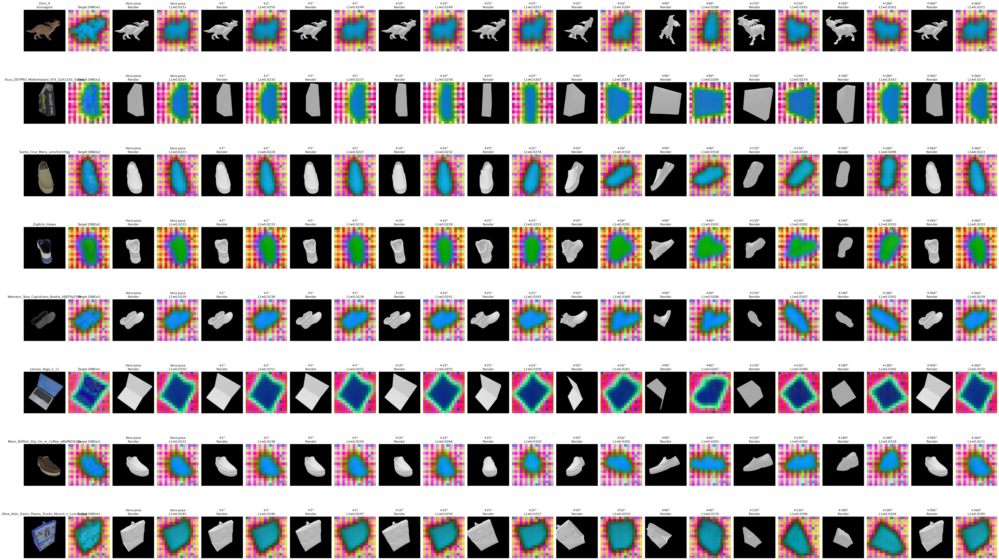

In [15]:
# =========================
# Visualizzazione target vs predictor vs render su sample reali dal batch
# Vera posa + N rotazioni errate (multipli di gradi su asse Y)
# Colonne: [Immagine] [Target DINOv2] [Render, Predictor] x len(rotazioni)
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]

N_SHOW = min(8, actual_bs)

# Lista delle rotazioni da testare: 0 = posa vera, poi offset crescenti
ROT_OFFSETS_DEG = [0.0, 2, 5, 10, 25.0, 50.0, 90, 150, 180, 360]
ROT_AXIS = 'y'
ROT_LABELS = ["Vera posa"] + [f"+{d:.0f}°" for d in ROT_OFFSETS_DEG[1:]]

R_offsets = [rotation_matrix(ROT_AXIS, d, device).unsqueeze(0).float() for d in ROT_OFFSETS_DEG]

N_COLS = 2 + 2 * len(ROT_OFFSETS_DEG)   # Immagine + Target + (Render, Predictor) per ogni rotazione
fig, axes = plt.subplots(N_SHOW, N_COLS, figsize=(2.4 * N_COLS, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    # --- Input immagine/maschera ---
    img_i = batch['image'][i].unsqueeze(0).to(device).float()
    mask_i = batch['mask'][i].to(device).float()

    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i

    # --- Camera / posa / contesto 3D ---
    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    context_dino = batch['context_3d'][i].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].unsqueeze(0).to(device).float()
    scale_t = batch['scale'][i].unsqueeze(0).to(device).float()

    # --- Numpy per render (K, centroid, scale) ---
    K_np = batch['K'][i].cpu().numpy()
    centroid_np = batch['centroid'][i].cpu().numpy()
    scale_np = float(batch['scale'][i].item())

    context_pose = batch["center_3d"][i].unsqueeze(0).to(device).float()                 # (B, N, 12)
    context_R = context_pose[..., :9].reshape(*context_pose.shape[:-1], 3, 3).to(device).float()  # (B, N, 3, 3)
    context_t = context_pose[..., 9:].to(device).float()  # (B, N, 3)

    # --- Maschera a livello di token ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    # --- Target DINOv2 (calcolato una sola volta per sample) ---
    with torch.no_grad():
        target = encoder2d(img_t)
    target_np = target.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    # --- Immagine di sfondo (denormalizzata) ---
    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    # --- Colonna 0: immagine originale ---
    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine" if i == 0 else model_name)
    axes[i, 0].axis('off')

    # --- Colonna 1: target DINOv2 ---
    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    print_str = f"{model_name}:"

    # --- Una coppia di colonne (Render, Predictor) per ogni rotazione ---
    for j, (R_off, label) in enumerate(zip(R_offsets, ROT_LABELS)):
        rot_j = torch.matmul(R_off, rot_t)  # se j==0, R_off è identità -> posa vera
        
        with torch.no_grad():
            pred = predictor(R_query=rot_j, t_query=trans_t,
                    context_dino=context_dino, context_R=context_R, context_t=context_t,
                    centroid=centroid_t, scale=scale_t,)
            l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()

        pred_np = pred.squeeze(0).cpu().numpy()
        pred_pca = pca.transform(pred_np)          # stessa PCA del target
        pred_map = to_rgb_map_local(pred_pca)

        # --- Render dell'oggetto con la posa ruotata ---
        R_np = rot_j.squeeze(0).cpu().numpy()
        t_np = trans_t.squeeze(0).cpu().numpy()
        rendered_img = render_gso_object(
            model_name, R_np, t_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )

        col_render = 2 + 2 * j
        col_pred = 2 + 2 * j + 1

        axes[i, col_render].imshow(rendered_img)
        axes[i, col_render].set_title(f"{label}\nRender")
        axes[i, col_render].axis('off')

        axes[i, col_pred].imshow(pred_map)
        axes[i, col_pred].set_title(f"{label}\nL1={l1_pred:.4f}")
        axes[i, col_pred].axis('off')

        print_str += f" | {label} L1={l1_pred:.4f}"

    print(print_str)

plt.tight_layout()
plt.show()

# TEST TRANSLATION (on Val)

Dino_4: | Vera posa L1=0.0251 | +0.02·s x L1=0.0251 | -0.02·s x L1=0.0251 | +0.05·s x L1=0.0251 | -0.05·s x L1=0.0251 | +0.10·s x L1=0.0251 | -0.10·s x L1=0.0251 | +0.25·s x L1=0.0251 | -0.25·s x L1=0.0251 | +0.50·s x L1=0.0251 | -0.50·s x L1=0.0251
Asus_Z87PRO_Motherboard_ATX_LGA1150_Socket: | Vera posa L1=0.0237 | +0.02·s x L1=0.0237 | -0.02·s x L1=0.0237 | +0.05·s x L1=0.0237 | -0.05·s x L1=0.0237 | +0.10·s x L1=0.0237 | -0.10·s x L1=0.0237 | +0.25·s x L1=0.0237 | -0.25·s x L1=0.0237 | +0.50·s x L1=0.0237 | -0.50·s x L1=0.0237
Santa_Cruz_Mens_umxTczr1Ygg: | Vera posa L1=0.0223 | +0.02·s x L1=0.0223 | -0.02·s x L1=0.0223 | +0.05·s x L1=0.0223 | -0.05·s x L1=0.0223 | +0.10·s x L1=0.0223 | -0.10·s x L1=0.0223 | +0.25·s x L1=0.0223 | -0.25·s x L1=0.0223 | +0.50·s x L1=0.0223 | -0.50·s x L1=0.0223
ZigKick_Hoops: | Vera posa L1=0.0233 | +0.02·s x L1=0.0233 | -0.02·s x L1=0.0233 | +0.05·s x L1=0.0233 | -0.05·s x L1=0.0233 | +0.10·s x L1=0.0233 | -0.10·s x L1=0.0233 | +0.25·s x L1=0.0233 | 

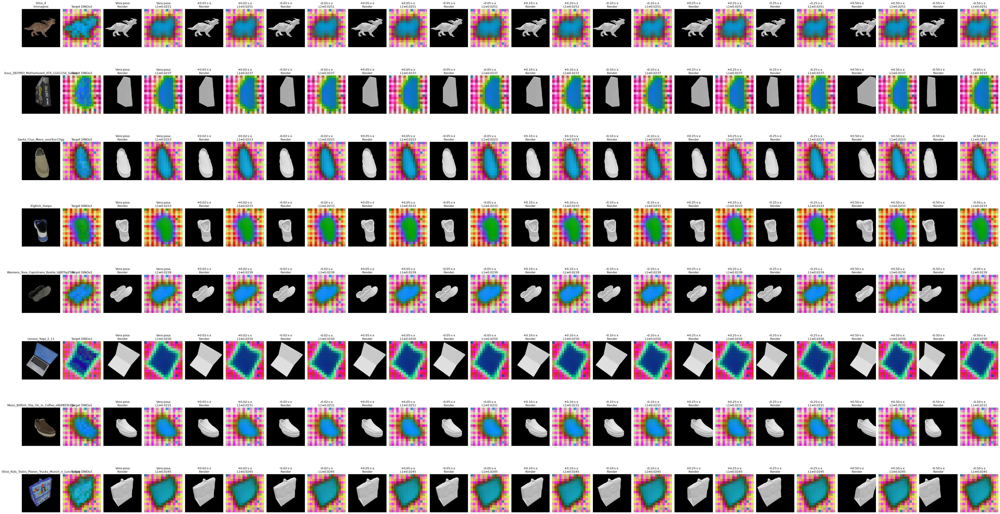

In [ ]:

#batch = next(sample_iter)
#actual_bs = batch['image'].shape[0]

N_SHOW = min(8, actual_bs)

# --- Configurazione traslazioni ---
TRANS_AXIS = 'x'   # 'x', 'y' o 'z' (camera frame)
AXIS_IDX = {'x': 0, 'y': 1, 'z': 2}[TRANS_AXIS]

TRANS_OFFSETS_FRAC = [0.0, 0.02, -0.02, 0.05, -0.05, 0.1, -0.1, 0.25, -0.25, 0.5, -0.5]
TRANS_LABELS = ["Vera posa"] + [
    f"{'+' if f > 0 else ''}{f:.2f}·s {TRANS_AXIS}" for f in TRANS_OFFSETS_FRAC[1:]
]

N_TRANS = len(TRANS_OFFSETS_FRAC)
N_COLS = 2 + 2 * N_TRANS   # Immagine + Target + (Render, Predictor) per ogni traslazione
fig, axes = plt.subplots(N_SHOW, N_COLS, figsize=(2.4 * N_COLS, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    # --- Input immagine/maschera ---
    img_i = batch['image'][i].unsqueeze(0).to(device).float()
    mask_i = batch['mask'][i].to(device).float()

    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i

    # --- Camera / posa / contesto 3D ---
    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    context_dino = batch['context_3d'][i].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].unsqueeze(0).to(device).float()
    scale_t = batch['scale'][i].unsqueeze(0).to(device).float()
               # (B, N, 12)
    context_R = centers_t[..., :9].reshape(*centers_t.shape[:-1], 3, 3).to(device).float()  # (B, N, 3, 3)
    context_t = centers_t[..., 9:].to(device).float()  # (B, N, 3)

    # --- Numpy per render (K, centroid, scale) ---
    K_np = batch['K'][i].cpu().numpy()
    centroid_np = batch['centroid'][i].cpu().numpy()
    scale_np = float(batch['scale'][i].item())

    # --- Maschera a livello di token ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    # --- Target DINOv2 (calcolato una sola volta per sample) ---
    with torch.no_grad():
        target = encoder2d(img_t)
    target_np = target.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    # --- Immagine di sfondo (denormalizzata) ---
    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    # --- Colonna 0: immagine originale ---
    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine" if i == 0 else model_name)
    axes[i, 0].axis('off')

    # --- Colonna 1: target DINOv2 ---
    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    print_str = f"{model_name}:"

    # --- Una coppia di colonne (Render, Predictor) per ogni traslazione ---
    for j, (offset_frac, label) in enumerate(zip(TRANS_OFFSETS_FRAC, TRANS_LABELS)):
        # Offset assoluto = frazione * scala dell'oggetto, applicato sull'asse scelto
        offset_abs = offset_frac * scale_t  # shape (1,)

        trans_j = trans_t.clone()
        trans_j[:, AXIS_IDX] = trans_j[:, AXIS_IDX] + offset_abs

        with torch.no_grad():
            pred = predictor(R_query=rot_t, t_query=trans_t,
                    context_dino=context_dino, context_R=context_R, context_t=context_t,
                    centroid=centroid_t, scale=scale_t)
            l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()

        pred_np = pred.squeeze(0).cpu().numpy()
        pred_pca = pca.transform(pred_np)          # stessa PCA del target
        pred_map = to_rgb_map_local(pred_pca)

        # --- Render dell'oggetto con la posa traslata ---
        R_np = rot_t.squeeze(0).cpu().numpy()
        t_np = trans_j.squeeze(0).cpu().numpy()
        rendered_img = render_gso_object(
            model_name, R_np, t_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )

        col_render = 2 + 2 * j
        col_pred = 2 + 2 * j + 1

        axes[i, col_render].imshow(rendered_img)
        axes[i, col_render].set_title(f"{label}\nRender")
        axes[i, col_render].axis('off')

        axes[i, col_pred].imshow(pred_map)
        axes[i, col_pred].set_title(f"{label}\nL1={l1_pred:.4f}")
        axes[i, col_pred].axis('off')

        print_str += f" | {label} L1={l1_pred:.4f}"

    print(print_str)

plt.tight_layout()
plt.show()

# TEST INFERENCE

In [ ]:
from scipy.spatial.transform import Rotation

## taking the data from a single object in the batch
Object = 15

img = batch['image'][Object].unsqueeze(0).to(device).float()   # (1,3,H,W)
mask = batch['mask'][Object].to(device).float()                 # (H,W)

R_real = batch['rot_matrix'][Object].unsqueeze(0).to(device).float()   # world-to-camera
t_real = batch['trans'][Object].unsqueeze(0).to(device).float()

R_real_np = R_real.squeeze(0).cpu().numpy()

centroid = batch['centroid'][Object].unsqueeze(0).to(device).float()   # (1, 3)
scale = batch['scale'][Object].unsqueeze(0).to(device).float()

context_t = batch['context_3d'][Object].unsqueeze(0).to(device).float()
centers_t = batch['center_3d'][Object].unsqueeze(0).to(device).float()

K = batch['K'][Object].unsqueeze(0).to(device).float()

mask_np = mask.squeeze().cpu().numpy()
token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)  # da Cell 8
token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()  # (1, N)

# --- Numpy per render ---
K_np = batch['K'][Object].cpu().numpy()
t_real_np = t_real.squeeze(0).cpu().numpy()
centroid_np = batch['centroid'][Object].cpu().numpy()
scale_np = float(batch['scale'][Object].item())
model_name = batch['model_name'][Object]

# --- Target DINOv2, calcolato una sola volta (non dipende dalla posa) ---
with torch.no_grad():
    target = encoder2d(img)

    ray_dirs, moment = _generate_rays(K, R_real, t_real, centroid, scale)
    pred = predictor(ray_dirs=ray_dirs, ray_moments=moment, context_features=context_t, context_centers=centers_t)

L1_real = masked_l1_per_sample(pred, target, token_mask_t).item()

# --- Immagine di sfondo ---
img_denorm = (img * STD_t + MEAN_t).clamp(0, 1)
bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

RANDOM_POSES = 10000
results = []

# Compute the geodesic distance between the predicted rotation and the real rotation
def geodesic_distance(R1, R2):
    R_diff = R1.T @ R2
    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))
    return np.rad2deg(angle)  # degree output


for i in range(RANDOM_POSES):
    R = Rotation.random().as_matrix()
    ray_dirs, moment = _generate_rays(K, torch.from_numpy(R).unsqueeze(0).to(device).float(),
                                       t_real, centroid, scale)

    with torch.no_grad():
        pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                          context_features=context_t, context_centers=centers_t)

    results.append({
        'R': R,
        'pred': pred,
        'L1': masked_l1_per_sample(pred, target, token_mask_t).item(),
        'diff': geodesic_distance(R_real_np, R)
    })

print(f"Best Pose: (L1={L1_real:.6f})")

results.sort(key=lambda x: x['L1'])
for i, res in enumerate(results):
    print(f"Pose {i}: L1={res['L1']:.4f}, R={res['diff']:.3f}°")
    if i == 10:
        break

results_by_diff = sorted(results, key=lambda x: x['diff'])
print(f"Best wrt geodesic distance {results_by_diff[0]['diff']:.3f}°, with L1={results_by_diff[0]['L1']:.4f}")

# =========================
# Plot: immagine, target, e le migliori 3 pose predette rispetto a L1
# =========================
TOP_K = 3
top_results = results[:TOP_K]   # già ordinati per L1 crescente

target_np = target.squeeze(0).cpu().numpy()
pca = PCA(n_components=3)
target_pca = pca.fit_transform(target_np)
target_map = to_rgb_map_local(target_pca)

N_COLS = 2 + 2 * TOP_K   # Immagine + Target + (Render, Predictor) per ogni top pose
fig, axes = plt.subplots(1, N_COLS, figsize=(2.4 * N_COLS, 4))

# --- Colonna 0: immagine originale ---
axes[0].imshow(bg_img)
axes[0].set_title(f"{model_name}\nImmagine")
axes[0].axis('off')

# --- Colonna 1: target DINOv2 ---
axes[1].imshow(target_map)
axes[1].set_title("Target DINOv2")
axes[1].axis('off')

# --- Una coppia di colonne (Render, Predictor) per ogni top-K pose ---
for j, res in enumerate(top_results):
    R_j = res['R']
    pred_np = res['pred'].squeeze(0).cpu().numpy()
    pred_pca = pca.transform(pred_np)          # stessa PCA del target
    pred_map = to_rgb_map_local(pred_pca)

    rendered_img = render_gso_object(
        model_name, R_j, t_real_np, K_np, img_size=bg_img.shape[:2],
        centroid=centroid_np, scale=scale_np,
    )

    col_render = 2 + 2 * j
    col_pred = 2 + 2 * j + 1

    axes[col_render].imshow(rendered_img)
    axes[col_render].set_title(f"Top {j+1} (L1={res['L1']:.4f})\nΔR={res['diff']:.1f}°\nRender")
    axes[col_render].axis('off')

    axes[col_pred].imshow(pred_map)
    axes[col_pred].set_title(f"Top {j+1}\nPredictor")
    axes[col_pred].axis('off')

plt.tight_layout()
plt.show()

TypeError: RenderPredictor.forward() got an unexpected keyword argument 'ray_dirs'

[OBJ 0] Dino_4: campionate 400 pose | Best Pose (R real) L1=0.0251
[OBJ 0] Best wrt geodesic distance 21.131°, con L1=0.0253
    step 0: loss=0.024864, grad_norm=0.001677
    step 20: loss=0.024755, grad_norm=0.001325
    step 40: loss=0.024703, grad_norm=0.001262
    step 60: loss=0.024676, grad_norm=0.002089
    step 80: loss=0.024674, grad_norm=0.001892
    step 100: loss=0.024672, grad_norm=0.004686
    step 120: loss=0.024669, grad_norm=0.002148
    step 140: loss=0.024669, grad_norm=0.001729
    step 160: loss=0.024668, grad_norm=0.000571
    step 180: loss=0.024668, grad_norm=0.000241
[OBJ 0] Refine: L1 0.0249 -> 0.0247 | ΔR 29.59° -> 41.53° | step usati: 199
    step 0: loss=0.024975, grad_norm=0.001783
    step 20: loss=0.024804, grad_norm=0.000810
    step 40: loss=0.024716, grad_norm=0.001172
    step 60: loss=0.024684, grad_norm=0.000932
    step 80: loss=0.024681, grad_norm=0.001559
    step 100: loss=0.024681, grad_norm=0.000576
    step 120: loss=0.024681, grad_norm=0.00

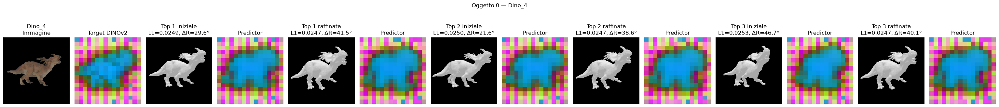

[OBJ 1] Asus_Z87PRO_Motherboard_ATX_LGA1150_Socket: campionate 400 pose | Best Pose (R real) L1=0.0222
[OBJ 1] Best wrt geodesic distance 8.159°, con L1=0.0230
    step 0: loss=0.022987, grad_norm=0.009930
    step 20: loss=0.021701, grad_norm=0.006174
    step 40: loss=0.021638, grad_norm=0.004238
    step 60: loss=0.021627, grad_norm=0.001341
    step 80: loss=0.021624, grad_norm=0.001253
    step 100: loss=0.021624, grad_norm=0.000507
    step 120: loss=0.021624, grad_norm=0.000252
    step 140: loss=0.021624, grad_norm=0.000027
[OBJ 1] Refine: L1 0.0230 -> 0.0216 | ΔR 8.16° -> 4.50° | step usati: 142
    step 0: loss=0.027079, grad_norm=0.032435
    step 20: loss=0.022813, grad_norm=0.007857
    step 40: loss=0.022801, grad_norm=0.004265
    step 60: loss=0.022773, grad_norm=0.001389
    step 80: loss=0.022770, grad_norm=0.001229
    step 100: loss=0.022770, grad_norm=0.000472
    step 120: loss=0.022770, grad_norm=0.000192
[OBJ 1] Refine: L1 0.0271 -> 0.0228 | ΔR 171.20° -> 177.13

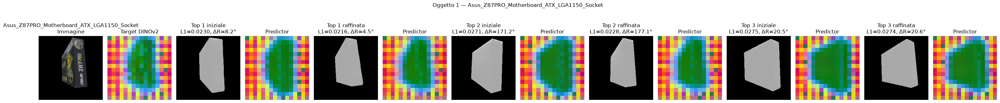

[OBJ 2] Santa_Cruz_Mens_umxTczr1Ygg: campionate 400 pose | Best Pose (R real) L1=0.0215
[OBJ 2] Best wrt geodesic distance 8.027°, con L1=0.0234
    step 0: loss=0.023360, grad_norm=0.003208
    step 20: loss=0.021470, grad_norm=0.006226
    step 40: loss=0.021444, grad_norm=0.001332
    step 60: loss=0.021437, grad_norm=0.002490
    step 80: loss=0.021433, grad_norm=0.000901
    step 100: loss=0.021432, grad_norm=0.000147
    step 120: loss=0.021432, grad_norm=0.000189
[OBJ 2] Refine: L1 0.0234 -> 0.0214 | ΔR 8.03° -> 2.03° | step usati: 131
    step 0: loss=0.026078, grad_norm=0.019037
    step 20: loss=0.023249, grad_norm=0.012681
    step 40: loss=0.021568, grad_norm=0.018515
    step 60: loss=0.021456, grad_norm=0.003974
    step 80: loss=0.021436, grad_norm=0.001510
    step 100: loss=0.021433, grad_norm=0.000507
    step 120: loss=0.021432, grad_norm=0.000178
    step 140: loss=0.021432, grad_norm=0.000069
[OBJ 2] Refine: L1 0.0261 -> 0.0214 | ΔR 18.40° -> 2.04° | step usati: 14

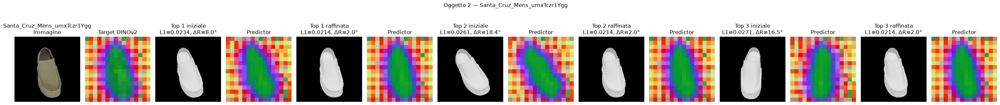

[OBJ 3] ZigKick_Hoops: campionate 400 pose | Best Pose (R real) L1=0.0233
[OBJ 3] Best wrt geodesic distance 14.558°, con L1=0.0256
    step 0: loss=0.025588, grad_norm=0.017624
    step 20: loss=0.022680, grad_norm=0.003602
    step 40: loss=0.022655, grad_norm=0.001838
    step 60: loss=0.022661, grad_norm=0.002145
    step 80: loss=0.022661, grad_norm=0.001908
    step 100: loss=0.022660, grad_norm=0.000043
    step 120: loss=0.022660, grad_norm=0.000178
[OBJ 3] Refine: L1 0.0256 -> 0.0227 | ΔR 14.56° -> 6.34° | step usati: 130
    step 0: loss=0.026793, grad_norm=0.023875
    step 20: loss=0.024391, grad_norm=0.008757
    step 40: loss=0.023005, grad_norm=0.008268
    step 60: loss=0.022661, grad_norm=0.005513
    step 80: loss=0.022657, grad_norm=0.000834
    step 100: loss=0.022657, grad_norm=0.000695
    step 120: loss=0.022656, grad_norm=0.000797
    step 140: loss=0.022656, grad_norm=0.000339
    step 160: loss=0.022655, grad_norm=0.000120
[OBJ 3] Refine: L1 0.0268 -> 0.0227 |

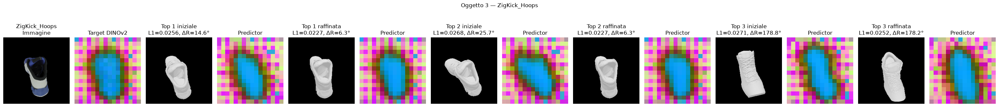

[OBJ 4] Womens_Teva_Capistrano_Bootie_ldjRT9yZ5Ht: campionate 400 pose | Best Pose (R real) L1=0.0228
[OBJ 4] Best wrt geodesic distance 13.264°, con L1=0.0259
    step 0: loss=0.025899, grad_norm=0.017286
    step 20: loss=0.023110, grad_norm=0.012960
    step 40: loss=0.022803, grad_norm=0.002865
    step 60: loss=0.022789, grad_norm=0.002245
    step 80: loss=0.022786, grad_norm=0.001727
    step 100: loss=0.022785, grad_norm=0.001055
    step 120: loss=0.022784, grad_norm=0.000239
[OBJ 4] Refine: L1 0.0259 -> 0.0228 | ΔR 13.26° -> 1.26° | step usati: 136
    step 0: loss=0.028567, grad_norm=0.023279
    step 20: loss=0.026034, grad_norm=0.010580
    step 40: loss=0.024248, grad_norm=0.019309
    step 60: loss=0.023165, grad_norm=0.010612
    step 80: loss=0.022810, grad_norm=0.003074
    step 100: loss=0.022785, grad_norm=0.002882
    step 120: loss=0.022778, grad_norm=0.001739
    step 140: loss=0.022777, grad_norm=0.005603
    step 160: loss=0.022774, grad_norm=0.001654
    step 

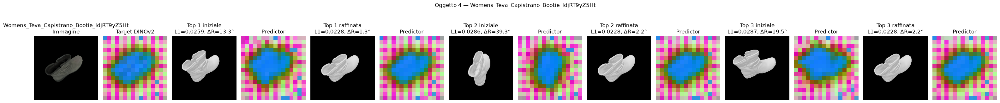

[OBJ 5] Lenovo_Yoga_2_11: campionate 400 pose | Best Pose (R real) L1=0.0240
[OBJ 5] Best wrt geodesic distance 21.879°, con L1=0.0258
    step 0: loss=0.025755, grad_norm=0.015665
    step 20: loss=0.024255, grad_norm=0.005587
    step 40: loss=0.023928, grad_norm=0.006397
    step 60: loss=0.023882, grad_norm=0.005145
    step 80: loss=0.023870, grad_norm=0.001643
    step 100: loss=0.023866, grad_norm=0.001799
    step 120: loss=0.023866, grad_norm=0.000395
    step 140: loss=0.023866, grad_norm=0.000356
[OBJ 5] Refine: L1 0.0258 -> 0.0239 | ΔR 21.88° -> 3.07° | step usati: 154
    step 0: loss=0.026630, grad_norm=0.008597
    step 20: loss=0.024614, grad_norm=0.012369
    step 40: loss=0.023953, grad_norm=0.002624
    step 60: loss=0.023892, grad_norm=0.003853
    step 80: loss=0.023883, grad_norm=0.001720
    step 100: loss=0.023881, grad_norm=0.001451
    step 120: loss=0.023880, grad_norm=0.000528
    step 140: loss=0.023880, grad_norm=0.000501
    step 160: loss=0.023880, grad_

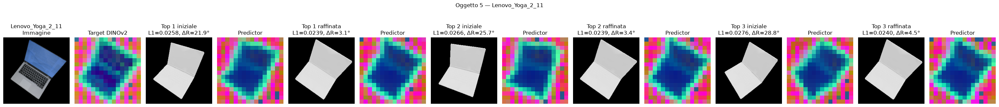

[OBJ 6] Mens_Billfish_Slip_On_in_Coffee_e8bPKE9Lfgo: campionate 400 pose | Best Pose (R real) L1=0.0219
[OBJ 6] Best wrt geodesic distance 20.820°, con L1=0.0305
    step 0: loss=0.025098, grad_norm=0.022337
    step 20: loss=0.022685, grad_norm=0.017278
    step 40: loss=0.021229, grad_norm=0.013461
    step 60: loss=0.021020, grad_norm=0.001517
    step 80: loss=0.021006, grad_norm=0.005101
    step 100: loss=0.021004, grad_norm=0.001059
    step 120: loss=0.021004, grad_norm=0.000788
    step 140: loss=0.021004, grad_norm=0.000213
[OBJ 6] Refine: L1 0.0251 -> 0.0210 | ΔR 25.24° -> 4.98° | step usati: 150
    step 0: loss=0.026430, grad_norm=0.006188
    step 20: loss=0.026062, grad_norm=0.006939
    step 40: loss=0.024489, grad_norm=0.005440
    step 60: loss=0.023827, grad_norm=0.008401
    step 80: loss=0.022969, grad_norm=0.010229
    step 100: loss=0.021670, grad_norm=0.021586
    step 120: loss=0.021029, grad_norm=0.003253
    step 140: loss=0.021015, grad_norm=0.007638
    ste

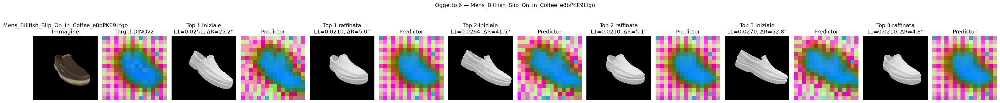

[OBJ 7] Olive_Kids_Trains_Planes_Trucks_Munch_n_Lunch_Bag: campionate 400 pose | Best Pose (R real) L1=0.0236
[OBJ 7] Best wrt geodesic distance 8.847°, con L1=0.0250
    step 0: loss=0.025042, grad_norm=0.003820
    step 20: loss=0.023461, grad_norm=0.009781
    step 40: loss=0.023307, grad_norm=0.003498
    step 60: loss=0.023283, grad_norm=0.002386
    step 80: loss=0.023279, grad_norm=0.000720
    step 100: loss=0.023278, grad_norm=0.000723
    step 120: loss=0.023278, grad_norm=0.000301
[OBJ 7] Refine: L1 0.0250 -> 0.0233 | ΔR 8.85° -> 3.57° | step usati: 138
    step 0: loss=0.025680, grad_norm=0.010336
    step 20: loss=0.024227, grad_norm=0.011039
    step 40: loss=0.023448, grad_norm=0.004905
    step 60: loss=0.023287, grad_norm=0.002291
    step 80: loss=0.023281, grad_norm=0.000902
    step 100: loss=0.023278, grad_norm=0.000449
    step 120: loss=0.023278, grad_norm=0.000190
    step 140: loss=0.023278, grad_norm=0.000100
[OBJ 7] Refine: L1 0.0257 -> 0.0233 | ΔR 19.17° -> 

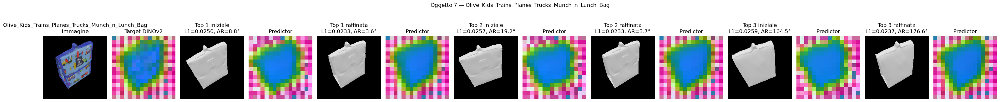

[OBJ 8] Perricone_MD_Blue_Plasma_Orbital: campionate 400 pose | Best Pose (R real) L1=0.0195
[OBJ 8] Best wrt geodesic distance 13.726°, con L1=0.0261
    step 0: loss=0.026098, grad_norm=0.019274
    step 20: loss=0.020015, grad_norm=0.032433
    step 40: loss=0.019474, grad_norm=0.007969
    step 60: loss=0.019439, grad_norm=0.002220
    step 80: loss=0.019432, grad_norm=0.002098
    step 100: loss=0.019429, grad_norm=0.000401
    step 120: loss=0.019429, grad_norm=0.000578
    step 140: loss=0.019429, grad_norm=0.000194
[OBJ 8] Refine: L1 0.0261 -> 0.0194 | ΔR 13.73° -> 1.08° | step usati: 146
    step 0: loss=0.026107, grad_norm=0.011207
    step 20: loss=0.020036, grad_norm=0.033740
    step 40: loss=0.019700, grad_norm=0.014122
    step 60: loss=0.019573, grad_norm=0.004107
    step 80: loss=0.019570, grad_norm=0.002403
    step 100: loss=0.019565, grad_norm=0.001214
    step 120: loss=0.019565, grad_norm=0.000908
    step 140: loss=0.019564, grad_norm=0.000285
[OBJ 8] Refine: L1

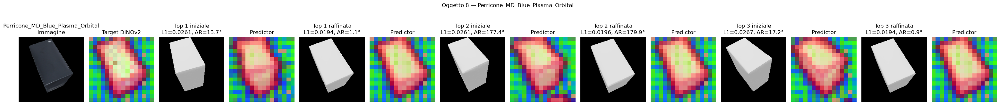

[OBJ 9] Ecoforms_Plant_Container_QP6HARVEST: campionate 400 pose | Best Pose (R real) L1=0.0195
[OBJ 9] Best wrt geodesic distance 16.975°, con L1=0.0221
    step 0: loss=0.022099, grad_norm=0.006533
    step 20: loss=0.020513, grad_norm=0.009572
    step 40: loss=0.019521, grad_norm=0.004802
    step 60: loss=0.019413, grad_norm=0.001944
    step 80: loss=0.019405, grad_norm=0.001370
    step 100: loss=0.019403, grad_norm=0.000431
    step 120: loss=0.019403, grad_norm=0.000098
[OBJ 9] Refine: L1 0.0221 -> 0.0194 | ΔR 178.61° -> 177.87° | step usati: 133
    step 0: loss=0.022113, grad_norm=0.007948
    step 20: loss=0.020440, grad_norm=0.009686
    step 40: loss=0.019558, grad_norm=0.004851
    step 60: loss=0.019450, grad_norm=0.002528
    step 80: loss=0.019447, grad_norm=0.000972
    step 100: loss=0.019446, grad_norm=0.000774
    step 120: loss=0.019446, grad_norm=0.000266
    step 140: loss=0.019446, grad_norm=0.000192
[OBJ 9] Refine: L1 0.0221 -> 0.0194 | ΔR 16.97° -> 2.01° | s

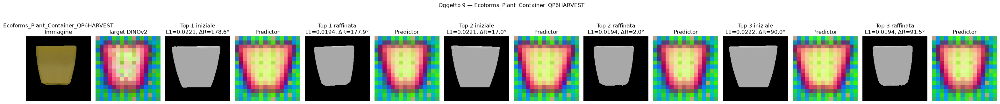

[OBJ 10] ASSORTED_VEGETABLE_SET: campionate 400 pose | Best Pose (R real) L1=0.0243
[OBJ 10] Best wrt geodesic distance 14.854°, con L1=0.0248
    step 0: loss=0.024807, grad_norm=0.003130
    step 20: loss=0.024472, grad_norm=0.002832
    step 40: loss=0.024312, grad_norm=0.001508
    step 60: loss=0.024284, grad_norm=0.003161
    step 80: loss=0.024282, grad_norm=0.001163
    step 100: loss=0.024282, grad_norm=0.000313
    step 120: loss=0.024282, grad_norm=0.000281
[OBJ 10] Refine: L1 0.0248 -> 0.0243 | ΔR 14.85° -> 7.87° | step usati: 139
    step 0: loss=0.025011, grad_norm=0.002555
    step 20: loss=0.024807, grad_norm=0.001866
    step 40: loss=0.024665, grad_norm=0.003635
    step 60: loss=0.024413, grad_norm=0.000976
    step 80: loss=0.024311, grad_norm=0.003950
    step 100: loss=0.024285, grad_norm=0.003671
    step 120: loss=0.024282, grad_norm=0.000956
    step 140: loss=0.024282, grad_norm=0.001571
    step 160: loss=0.024282, grad_norm=0.001840
    step 180: loss=0.0242

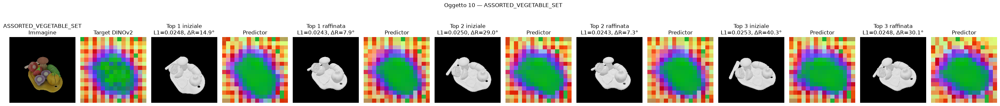

[OBJ 11] Asus_M5A99FX_PRO_R20_Motherboard_ATX_Socket_AM3: campionate 400 pose | Best Pose (R real) L1=0.0210
[OBJ 11] Best wrt geodesic distance 24.678°, con L1=0.0310
    step 0: loss=0.027218, grad_norm=0.009378
    step 20: loss=0.027119, grad_norm=0.002960
    step 40: loss=0.027119, grad_norm=0.005350
    step 60: loss=0.027117, grad_norm=0.000433
    step 80: loss=0.027117, grad_norm=0.000997
    step 100: loss=0.027117, grad_norm=0.000072
[OBJ 11] Refine: L1 0.0272 -> 0.0271 | ΔR 116.93° -> 117.91° | step usati: 112
    step 0: loss=0.027325, grad_norm=0.007277
    step 20: loss=0.027025, grad_norm=0.001994
    step 40: loss=0.026768, grad_norm=0.005810
    step 60: loss=0.026527, grad_norm=0.009474
    step 80: loss=0.026202, grad_norm=0.004884
    step 100: loss=0.026047, grad_norm=0.004599
    step 120: loss=0.025795, grad_norm=0.009121
    step 140: loss=0.025799, grad_norm=0.000857
    step 160: loss=0.025785, grad_norm=0.004697
    step 180: loss=0.025781, grad_norm=0.0021

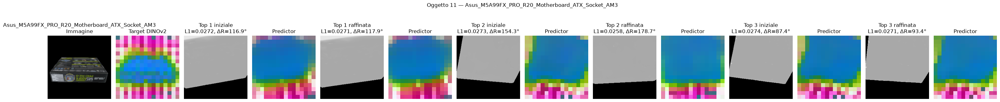

[OBJ 12] Creatine_Monohydrate: campionate 400 pose | Best Pose (R real) L1=0.0186
[OBJ 12] Best wrt geodesic distance 13.246°, con L1=0.0250
    step 0: loss=0.024967, grad_norm=0.037337
    step 20: loss=0.017639, grad_norm=0.047866
    step 40: loss=0.017092, grad_norm=0.020216
    step 60: loss=0.017007, grad_norm=0.004194
    step 80: loss=0.016971, grad_norm=0.003258
    step 100: loss=0.016971, grad_norm=0.000840
    step 120: loss=0.016968, grad_norm=0.001502
    step 140: loss=0.016968, grad_norm=0.000617
    step 160: loss=0.016968, grad_norm=0.000218
[OBJ 12] Refine: L1 0.0250 -> 0.0170 | ΔR 16.17° -> 7.56° | step usati: 172
    step 0: loss=0.025036, grad_norm=0.064447
    step 20: loss=0.017630, grad_norm=0.063575
    step 40: loss=0.017088, grad_norm=0.019954
    step 60: loss=0.017008, grad_norm=0.005654
    step 80: loss=0.017000, grad_norm=0.003183
    step 100: loss=0.016999, grad_norm=0.001795
    step 120: loss=0.016998, grad_norm=0.000525
    step 140: loss=0.016998

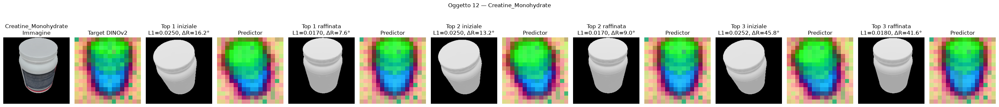

[OBJ 13] Dell_Ink_Cartridge: campionate 400 pose | Best Pose (R real) L1=0.0211
[OBJ 13] Best wrt geodesic distance 25.119°, con L1=0.0254
    step 0: loss=0.025405, grad_norm=0.011733
    step 20: loss=0.024220, grad_norm=0.008485
    step 40: loss=0.024003, grad_norm=0.006821
    step 60: loss=0.023963, grad_norm=0.004637
    step 80: loss=0.023954, grad_norm=0.004189
    step 100: loss=0.023953, grad_norm=0.002006
    step 120: loss=0.023953, grad_norm=0.000495
    step 140: loss=0.023953, grad_norm=0.000432
[OBJ 13] Refine: L1 0.0254 -> 0.0240 | ΔR 25.12° -> 19.92° | step usati: 159
    step 0: loss=0.026403, grad_norm=0.010777
    step 20: loss=0.025484, grad_norm=0.009136
    step 40: loss=0.025156, grad_norm=0.006564
    step 60: loss=0.023080, grad_norm=0.011434
    step 80: loss=0.021513, grad_norm=0.001563
    step 100: loss=0.021506, grad_norm=0.004566
    step 120: loss=0.021462, grad_norm=0.002332
    step 140: loss=0.021454, grad_norm=0.001186
    step 160: loss=0.021454,

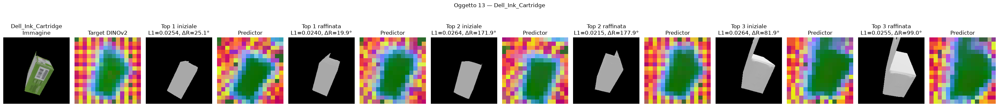

[OBJ 14] Ecoforms_Plant_Container_GP16A_Coral: campionate 400 pose | Best Pose (R real) L1=0.0178
[OBJ 14] Best wrt geodesic distance 5.537°, con L1=0.0183
    step 0: loss=0.018180, grad_norm=0.011996
    step 20: loss=0.017801, grad_norm=0.002040
    step 40: loss=0.017794, grad_norm=0.002761
    step 60: loss=0.017791, grad_norm=0.003606
    step 80: loss=0.017790, grad_norm=0.002050
    step 100: loss=0.017790, grad_norm=0.002670
    step 120: loss=0.017789, grad_norm=0.001324
    step 140: loss=0.017789, grad_norm=0.001554
    step 160: loss=0.017789, grad_norm=0.000108
[OBJ 14] Refine: L1 0.0182 -> 0.0178 | ΔR 55.33° -> 55.26° | step usati: 180
    step 0: loss=0.018206, grad_norm=0.010730
    step 20: loss=0.017798, grad_norm=0.004470
    step 40: loss=0.017792, grad_norm=0.002781
    step 60: loss=0.017797, grad_norm=0.000552
    step 80: loss=0.017796, grad_norm=0.000449
    step 100: loss=0.017796, grad_norm=0.000355
    step 120: loss=0.017796, grad_norm=0.000096
[OBJ 14] Re

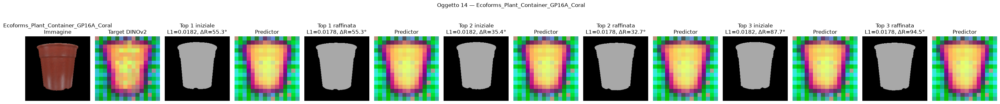

[OBJ 15] FisherPrice_Make_A_Match_Game_Thomas_Friends: campionate 400 pose | Best Pose (R real) L1=0.0230
[OBJ 15] Best wrt geodesic distance 19.112°, con L1=0.0325
    step 0: loss=0.026125, grad_norm=0.024368
    step 20: loss=0.024940, grad_norm=0.009427
    step 40: loss=0.024903, grad_norm=0.008868
    step 60: loss=0.024890, grad_norm=0.005256
    step 80: loss=0.024880, grad_norm=0.003524
    step 100: loss=0.024880, grad_norm=0.001957
    step 120: loss=0.024880, grad_norm=0.000718
    step 140: loss=0.024880, grad_norm=0.000586
[OBJ 15] Refine: L1 0.0261 -> 0.0249 | ΔR 177.63° -> 179.08° | step usati: 151
    step 0: loss=0.026925, grad_norm=0.096764
    step 20: loss=0.025150, grad_norm=0.009643
    step 40: loss=0.024950, grad_norm=0.012056
    step 60: loss=0.025026, grad_norm=0.014754
    step 80: loss=0.024980, grad_norm=0.010513
    step 100: loss=0.024947, grad_norm=0.009178
    step 120: loss=0.024932, grad_norm=0.020839
    step 140: loss=0.024923, grad_norm=0.007846


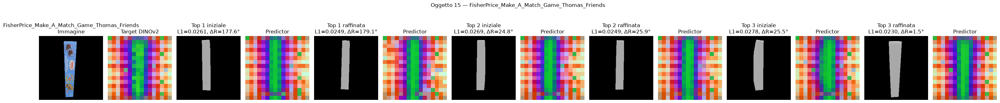

[OBJ 16] Mens_Mako_Canoe_Moc_2Eye_Boat_Shoe_in_Coffee_K9e8FoV73uZ: campionate 400 pose | Best Pose (R real) L1=0.0208
[OBJ 16] Best wrt geodesic distance 7.185°, con L1=0.0226
    step 0: loss=0.022572, grad_norm=0.036357
    step 20: loss=0.021309, grad_norm=0.019302
    step 40: loss=0.021197, grad_norm=0.003191
    step 60: loss=0.021195, grad_norm=0.008710
    step 80: loss=0.021191, grad_norm=0.004327
    step 100: loss=0.021190, grad_norm=0.002500
    step 120: loss=0.021190, grad_norm=0.002066
    step 140: loss=0.021190, grad_norm=0.001100
    step 160: loss=0.021190, grad_norm=0.000754
    step 180: loss=0.021190, grad_norm=0.001717
    step 200: loss=0.021190, grad_norm=0.000198
    step 220: loss=0.021190, grad_norm=0.001228
    step 240: loss=0.021190, grad_norm=0.001937
    step 260: loss=0.021190, grad_norm=0.000863
    step 280: loss=0.021190, grad_norm=0.001507
    step 300: loss=0.021190, grad_norm=0.002628
    step 320: loss=0.021190, grad_norm=0.002137
    step 340: 

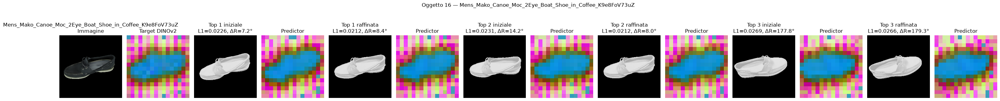

[OBJ 17] Poppin_File_Sorter_Pink: campionate 400 pose | Best Pose (R real) L1=0.0253
[OBJ 17] Best wrt geodesic distance 13.969°, con L1=0.0258
    step 0: loss=0.025832, grad_norm=0.006723
    step 20: loss=0.025192, grad_norm=0.003816
    step 40: loss=0.025197, grad_norm=0.003159
    step 60: loss=0.025197, grad_norm=0.004072
    step 80: loss=0.025198, grad_norm=0.001060
    step 100: loss=0.025196, grad_norm=0.001321
    step 120: loss=0.025196, grad_norm=0.000225
    step 140: loss=0.025196, grad_norm=0.000142
[OBJ 17] Refine: L1 0.0258 -> 0.0252 | ΔR 13.97° -> 8.37° | step usati: 147
    step 0: loss=0.026071, grad_norm=0.010063
    step 20: loss=0.025357, grad_norm=0.002997
    step 40: loss=0.024986, grad_norm=0.000758
    step 60: loss=0.024980, grad_norm=0.002634
    step 80: loss=0.024918, grad_norm=0.001850
    step 100: loss=0.024915, grad_norm=0.003363
    step 120: loss=0.024902, grad_norm=0.006048
    step 140: loss=0.024898, grad_norm=0.002487
    step 160: loss=0.024

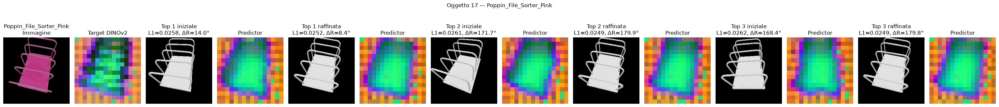

[OBJ 18] Reebok_COMFORT_REEFRESH_FLIP: campionate 400 pose | Best Pose (R real) L1=0.0212
[OBJ 18] Best wrt geodesic distance 9.099°, con L1=0.0249
    step 0: loss=0.024846, grad_norm=0.050921
    step 20: loss=0.021545, grad_norm=0.015759
    step 40: loss=0.021272, grad_norm=0.005163
    step 60: loss=0.021152, grad_norm=0.003041
    step 80: loss=0.021105, grad_norm=0.001044
    step 100: loss=0.021103, grad_norm=0.001074
    step 120: loss=0.021102, grad_norm=0.000824
    step 140: loss=0.021102, grad_norm=0.000383
    step 160: loss=0.021102, grad_norm=0.000095
[OBJ 18] Refine: L1 0.0248 -> 0.0211 | ΔR 26.79° -> 6.71° | step usati: 163
    step 0: loss=0.024882, grad_norm=0.019336
    step 20: loss=0.022370, grad_norm=0.001974
    step 40: loss=0.022210, grad_norm=0.001433
    step 60: loss=0.022206, grad_norm=0.001628
    step 80: loss=0.022204, grad_norm=0.000832
    step 100: loss=0.022204, grad_norm=0.000319
    step 120: loss=0.022204, grad_norm=0.000242
[OBJ 18] Refine: L1 

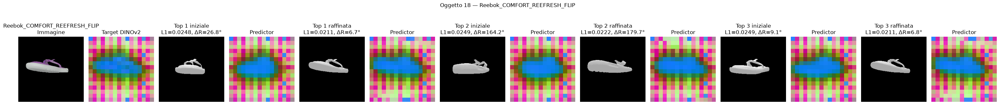

[OBJ 19] Black_and_Decker_PBJ2000_FusionBlade_Blender_Jars: campionate 400 pose | Best Pose (R real) L1=0.0242
[OBJ 19] Best wrt geodesic distance 9.295°, con L1=0.0276
    step 0: loss=0.026514, grad_norm=0.024139
    step 20: loss=0.024199, grad_norm=0.002901
    step 40: loss=0.024146, grad_norm=0.003362
    step 60: loss=0.024138, grad_norm=0.001594
    step 80: loss=0.024134, grad_norm=0.001089
    step 100: loss=0.024132, grad_norm=0.000754
    step 120: loss=0.024132, grad_norm=0.000550
    step 140: loss=0.024132, grad_norm=0.000173
[OBJ 19] Refine: L1 0.0265 -> 0.0241 | ΔR 176.23° -> 178.34° | step usati: 142
    step 0: loss=0.027144, grad_norm=0.025406
    step 20: loss=0.024894, grad_norm=0.004886
    step 40: loss=0.024401, grad_norm=0.004945
    step 60: loss=0.024146, grad_norm=0.004319
    step 80: loss=0.024136, grad_norm=0.001418
    step 100: loss=0.024132, grad_norm=0.000173
    step 120: loss=0.024132, grad_norm=0.000346
    step 140: loss=0.024132, grad_norm=0.000

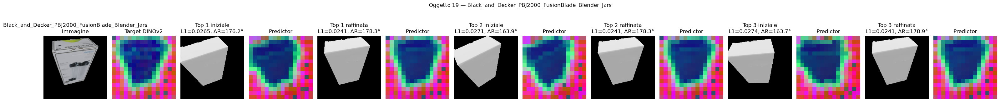

[OBJ 20] STACKING_BEAR: campionate 400 pose | Best Pose (R real) L1=0.0227
[OBJ 20] Best wrt geodesic distance 20.371°, con L1=0.0264
    step 0: loss=0.025866, grad_norm=0.006657
    step 20: loss=0.023885, grad_norm=0.012826
    step 40: loss=0.023224, grad_norm=0.011418
    step 60: loss=0.023220, grad_norm=0.004807
    step 80: loss=0.023167, grad_norm=0.002373
    step 100: loss=0.023154, grad_norm=0.000847
    step 120: loss=0.023154, grad_norm=0.000910
    step 140: loss=0.023154, grad_norm=0.000669
    step 160: loss=0.023154, grad_norm=0.000073
[OBJ 20] Refine: L1 0.0259 -> 0.0232 | ΔR 102.86° -> 94.44° | step usati: 170
    step 0: loss=0.026083, grad_norm=0.013189
    step 20: loss=0.024691, grad_norm=0.010240
    step 40: loss=0.024433, grad_norm=0.023666
    step 60: loss=0.024220, grad_norm=0.004648
    step 80: loss=0.024217, grad_norm=0.005044
    step 100: loss=0.024204, grad_norm=0.003763
    step 120: loss=0.024203, grad_norm=0.001809
    step 140: loss=0.024203, gra

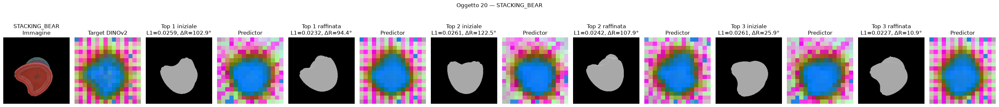

[OBJ 21] DINNING_ROOM_FURNITURE_SET_1: campionate 400 pose | Best Pose (R real) L1=0.0267
[OBJ 21] Best wrt geodesic distance 19.143°, con L1=0.0292
    step 0: loss=0.028076, grad_norm=0.004207
    step 20: loss=0.027406, grad_norm=0.003976
    step 40: loss=0.027153, grad_norm=0.002831
    step 60: loss=0.026830, grad_norm=0.004688
    step 80: loss=0.026556, grad_norm=0.004617
    step 100: loss=0.026530, grad_norm=0.002231
    step 120: loss=0.026530, grad_norm=0.001178
    step 140: loss=0.026529, grad_norm=0.000614
    step 160: loss=0.026529, grad_norm=0.000215
[OBJ 21] Refine: L1 0.0281 -> 0.0265 | ΔR 140.13° -> 160.40° | step usati: 171
    step 0: loss=0.028542, grad_norm=0.012608
    step 20: loss=0.027727, grad_norm=0.001282
    step 40: loss=0.027704, grad_norm=0.001385
    step 60: loss=0.027693, grad_norm=0.001405
    step 80: loss=0.027692, grad_norm=0.000945
    step 100: loss=0.027692, grad_norm=0.000283
    step 120: loss=0.027692, grad_norm=0.000262
[OBJ 21] Refine:

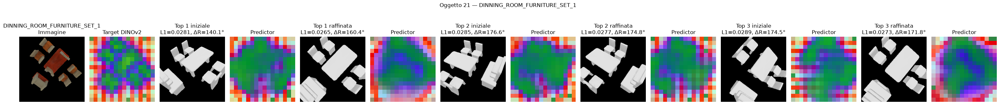

[OBJ 22] Melissa_Doug_Felt_Food_Pizza_Set: campionate 400 pose | Best Pose (R real) L1=0.0246
[OBJ 22] Best wrt geodesic distance 8.116°, con L1=0.0252
    step 0: loss=0.025213, grad_norm=0.004705
    step 20: loss=0.024877, grad_norm=0.003044
    step 40: loss=0.024833, grad_norm=0.001143
    step 60: loss=0.024811, grad_norm=0.001424
    step 80: loss=0.024807, grad_norm=0.003356
    step 100: loss=0.024805, grad_norm=0.001714
    step 120: loss=0.024804, grad_norm=0.000895
    step 140: loss=0.024804, grad_norm=0.001448
    step 160: loss=0.024805, grad_norm=0.001620
    step 180: loss=0.024807, grad_norm=0.002053
    step 200: loss=0.024806, grad_norm=0.001426
    step 220: loss=0.024806, grad_norm=0.000058
    step 240: loss=0.024806, grad_norm=0.000151
[OBJ 22] Refine: L1 0.0252 -> 0.0248 | ΔR 87.48° -> 81.87° | step usati: 259
    step 0: loss=0.025214, grad_norm=0.008598
    step 20: loss=0.024653, grad_norm=0.001004
    step 40: loss=0.024646, grad_norm=0.000497
    step 60: 

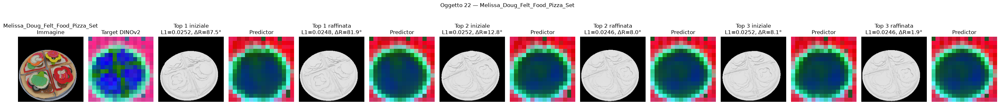

[OBJ 23] Nestle_Nesquik_Chocolate_Powder_Flavored_Milk_Additive_109_Oz_Canister: campionate 400 pose | Best Pose (R real) L1=0.0248
[OBJ 23] Best wrt geodesic distance 21.562°, con L1=0.0259
    step 0: loss=0.025517, grad_norm=0.005786
    step 20: loss=0.024921, grad_norm=0.005696
    step 40: loss=0.024779, grad_norm=0.002693
    step 60: loss=0.024563, grad_norm=0.004691
    step 80: loss=0.024505, grad_norm=0.001430
    step 100: loss=0.024503, grad_norm=0.001482
    step 120: loss=0.024501, grad_norm=0.002360
    step 140: loss=0.024500, grad_norm=0.000633
    step 160: loss=0.024499, grad_norm=0.000380
    step 180: loss=0.024499, grad_norm=0.000120
[OBJ 23] Refine: L1 0.0255 -> 0.0245 | ΔR 29.22° -> 10.75° | step usati: 181
    step 0: loss=0.025891, grad_norm=0.003497
    step 20: loss=0.024903, grad_norm=0.003393
    step 40: loss=0.024675, grad_norm=0.002099
    step 60: loss=0.024511, grad_norm=0.004552
    step 80: loss=0.024507, grad_norm=0.000666
    step 100: loss=0.024

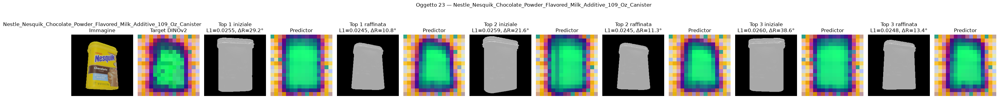

[OBJ 24] LACING_SHEEP: campionate 400 pose | Best Pose (R real) L1=0.0267
[OBJ 24] Best wrt geodesic distance 34.219°, con L1=0.0275
    step 0: loss=0.027089, grad_norm=0.005590
    step 20: loss=0.026666, grad_norm=0.002193
    step 40: loss=0.026655, grad_norm=0.001463
    step 60: loss=0.026633, grad_norm=0.001069
    step 80: loss=0.026631, grad_norm=0.001347
    step 100: loss=0.026631, grad_norm=0.000630
    step 120: loss=0.026630, grad_norm=0.000269
    step 140: loss=0.026630, grad_norm=0.000050
[OBJ 24] Refine: L1 0.0271 -> 0.0266 | ΔR 163.24° -> 156.56° | step usati: 143
    step 0: loss=0.027141, grad_norm=0.004077
    step 20: loss=0.026752, grad_norm=0.001358
    step 40: loss=0.026673, grad_norm=0.002472
    step 60: loss=0.026655, grad_norm=0.001739
    step 80: loss=0.026651, grad_norm=0.000894
    step 100: loss=0.026650, grad_norm=0.000241
    step 120: loss=0.026650, grad_norm=0.000076
    step 140: loss=0.026650, grad_norm=0.000081
[OBJ 24] Refine: L1 0.0271 -> 0.

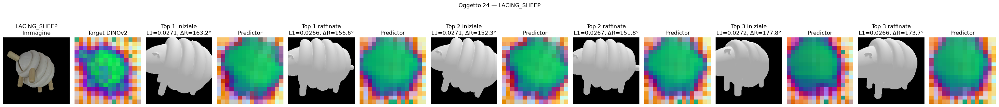

[OBJ 25] InterDesign_Over_Door: campionate 400 pose | Best Pose (R real) L1=0.0274
[OBJ 25] Best wrt geodesic distance 18.917°, con L1=0.0295
    step 0: loss=0.028298, grad_norm=0.018083
    step 20: loss=0.028172, grad_norm=0.002489
    step 40: loss=0.028097, grad_norm=0.007718
    step 60: loss=0.028073, grad_norm=0.013299
    step 80: loss=0.028063, grad_norm=0.007336
    step 100: loss=0.028061, grad_norm=0.002736
    step 120: loss=0.028060, grad_norm=0.001075
    step 140: loss=0.028060, grad_norm=0.000263
[OBJ 25] Refine: L1 0.0283 -> 0.0281 | ΔR 132.57° -> 135.85° | step usati: 153
    step 0: loss=0.029029, grad_norm=0.006513
    step 20: loss=0.028465, grad_norm=0.012363
    step 40: loss=0.028055, grad_norm=0.004023
    step 60: loss=0.027477, grad_norm=0.002922
    step 80: loss=0.027455, grad_norm=0.001259
    step 100: loss=0.027454, grad_norm=0.000405
    step 120: loss=0.027454, grad_norm=0.000365
[OBJ 25] Refine: L1 0.0290 -> 0.0275 | ΔR 137.00° -> 141.31° | step usa

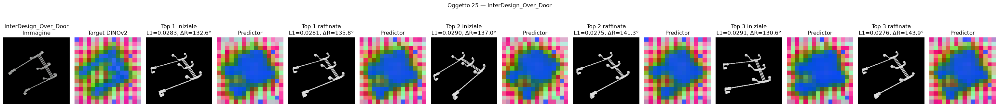

[OBJ 26] Perricone_MD_High_Potency_Evening_Repair: campionate 400 pose | Best Pose (R real) L1=0.0209
[OBJ 26] Best wrt geodesic distance 14.535°, con L1=0.0236
    step 0: loss=0.023163, grad_norm=0.027202
    step 20: loss=0.020409, grad_norm=0.010227
    step 40: loss=0.020204, grad_norm=0.013053
    step 60: loss=0.020157, grad_norm=0.006814
    step 80: loss=0.020150, grad_norm=0.006812
    step 100: loss=0.020156, grad_norm=0.019295
    step 120: loss=0.020149, grad_norm=0.007548
    step 140: loss=0.020149, grad_norm=0.008658
    step 160: loss=0.020147, grad_norm=0.001673
    step 180: loss=0.020148, grad_norm=0.009142
    step 200: loss=0.020161, grad_norm=0.007417
    step 220: loss=0.020155, grad_norm=0.011827
    step 240: loss=0.020158, grad_norm=0.009502
    step 260: loss=0.020155, grad_norm=0.008394
    step 280: loss=0.020149, grad_norm=0.007313
    step 300: loss=0.020154, grad_norm=0.006784
    step 320: loss=0.020148, grad_norm=0.003393
    step 340: loss=0.020147, 

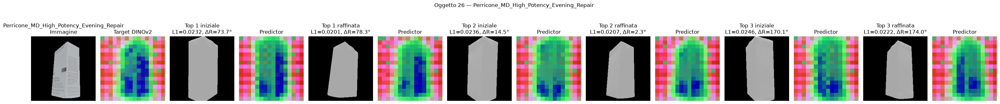

[OBJ 27] JarroSil_Activated_Silicon: campionate 400 pose | Best Pose (R real) L1=0.0202
[OBJ 27] Best wrt geodesic distance 21.537°, con L1=0.0282
    step 0: loss=0.026346, grad_norm=0.023580
    step 20: loss=0.024763, grad_norm=0.010446
    step 40: loss=0.023257, grad_norm=0.012451
    step 60: loss=0.020091, grad_norm=0.006949
    step 80: loss=0.020129, grad_norm=0.008491
    step 100: loss=0.020066, grad_norm=0.005844
    step 120: loss=0.020058, grad_norm=0.000630
    step 140: loss=0.020057, grad_norm=0.000317
    step 160: loss=0.020057, grad_norm=0.000091
[OBJ 27] Refine: L1 0.0263 -> 0.0201 | ΔR 31.26° -> 1.91° | step usati: 167
    step 0: loss=0.027033, grad_norm=0.019296
    step 20: loss=0.025325, grad_norm=0.007542
    step 40: loss=0.023250, grad_norm=0.012326
    step 60: loss=0.020085, grad_norm=0.006926
    step 80: loss=0.020195, grad_norm=0.011676
    step 100: loss=0.020059, grad_norm=0.001942
    step 120: loss=0.020059, grad_norm=0.001560
    step 140: loss=0.

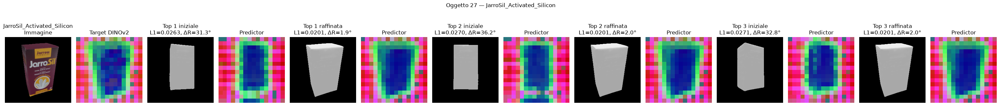

[OBJ 28] REEF_BRAIDED_CUSHION: campionate 400 pose | Best Pose (R real) L1=0.0212
[OBJ 28] Best wrt geodesic distance 26.503°, con L1=0.0310
    step 0: loss=0.026305, grad_norm=0.019812
    step 20: loss=0.023825, grad_norm=0.016207
    step 40: loss=0.022598, grad_norm=0.013698
    step 60: loss=0.020713, grad_norm=0.005872
    step 80: loss=0.020515, grad_norm=0.003755
    step 100: loss=0.020448, grad_norm=0.001094
    step 120: loss=0.020412, grad_norm=0.000779
    step 140: loss=0.020411, grad_norm=0.000711
    step 160: loss=0.020410, grad_norm=0.000226
    step 180: loss=0.020410, grad_norm=0.000070
[OBJ 28] Refine: L1 0.0263 -> 0.0204 | ΔR 36.73° -> 4.70° | step usati: 196
    step 0: loss=0.026309, grad_norm=0.023663
    step 20: loss=0.026021, grad_norm=0.004634
    step 40: loss=0.025956, grad_norm=0.004593
    step 60: loss=0.025948, grad_norm=0.002047
    step 80: loss=0.025937, grad_norm=0.001809
    step 100: loss=0.025937, grad_norm=0.000890
    step 120: loss=0.025937

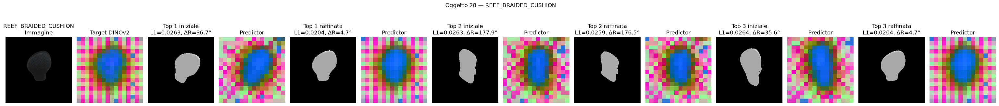

[OBJ 29] Rubbermaid_Large_Drainer: campionate 400 pose | Best Pose (R real) L1=0.0267
[OBJ 29] Best wrt geodesic distance 34.105°, con L1=0.0295
    step 0: loss=0.028635, grad_norm=0.002568
    step 20: loss=0.027968, grad_norm=0.001664
    step 40: loss=0.027817, grad_norm=0.001700
    step 60: loss=0.027807, grad_norm=0.001436
    step 80: loss=0.027784, grad_norm=0.001195
    step 100: loss=0.027770, grad_norm=0.000712
    step 120: loss=0.027736, grad_norm=0.002495
    step 140: loss=0.027738, grad_norm=0.001121
    step 160: loss=0.027737, grad_norm=0.000518
    step 180: loss=0.027737, grad_norm=0.000164
[OBJ 29] Refine: L1 0.0286 -> 0.0277 | ΔR 110.67° -> 131.22° | step usati: 199
    step 0: loss=0.028701, grad_norm=0.006292
    step 20: loss=0.027928, grad_norm=0.002539
    step 40: loss=0.027821, grad_norm=0.001145
    step 60: loss=0.027801, grad_norm=0.001297
    step 80: loss=0.027786, grad_norm=0.001079
    step 100: loss=0.027778, grad_norm=0.001574
    step 120: loss=0

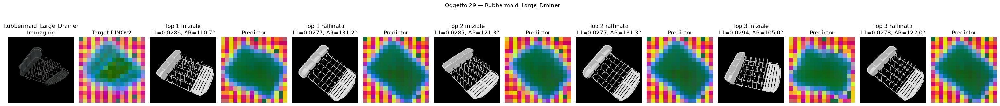

[OBJ 30] Paint_Maker: campionate 400 pose | Best Pose (R real) L1=0.0231
[OBJ 30] Best wrt geodesic distance 32.574°, con L1=0.0261
    step 0: loss=0.026127, grad_norm=0.002966
    step 20: loss=0.026045, grad_norm=0.001918
    step 40: loss=0.026028, grad_norm=0.002212
    step 60: loss=0.026024, grad_norm=0.001169
    step 80: loss=0.026021, grad_norm=0.001841
    step 100: loss=0.026021, grad_norm=0.000287
    step 120: loss=0.026021, grad_norm=0.000181
[OBJ 30] Refine: L1 0.0261 -> 0.0260 | ΔR 32.57° -> 29.77° | step usati: 128
    step 0: loss=0.026236, grad_norm=0.002465
    step 20: loss=0.025913, grad_norm=0.003242
    step 40: loss=0.025909, grad_norm=0.002392
    step 60: loss=0.025905, grad_norm=0.001896
    step 80: loss=0.025904, grad_norm=0.002284
    step 100: loss=0.025901, grad_norm=0.003942
    step 120: loss=0.025899, grad_norm=0.000761
    step 140: loss=0.025898, grad_norm=0.000081
    step 160: loss=0.025898, grad_norm=0.000196
[OBJ 30] Refine: L1 0.0262 -> 0.025

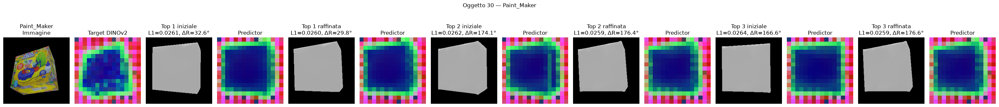

[OBJ 31] GEARS_PUZZLES_STANDARD_gcYxhNHhKlI: campionate 400 pose | Best Pose (R real) L1=0.0261
[OBJ 31] Best wrt geodesic distance 13.323°, con L1=0.0260
    step 0: loss=0.025971, grad_norm=0.006489
    step 20: loss=0.025696, grad_norm=0.000962
    step 40: loss=0.025695, grad_norm=0.000816
    step 60: loss=0.025694, grad_norm=0.000276
    step 80: loss=0.025694, grad_norm=0.000100
[OBJ 31] Refine: L1 0.0260 -> 0.0257 | ΔR 13.32° -> 14.61° | step usati: 86
    step 0: loss=0.026150, grad_norm=0.008975
    step 20: loss=0.026158, grad_norm=0.005966
    step 40: loss=0.026129, grad_norm=0.000848
    step 60: loss=0.026127, grad_norm=0.001930
    step 80: loss=0.026129, grad_norm=0.002333
    step 100: loss=0.026127, grad_norm=0.001334
    step 120: loss=0.026128, grad_norm=0.002117
    step 140: loss=0.026126, grad_norm=0.001215
    step 160: loss=0.026128, grad_norm=0.002202
    step 180: loss=0.026127, grad_norm=0.002134
    step 200: loss=0.026126, grad_norm=0.000768
    step 220:

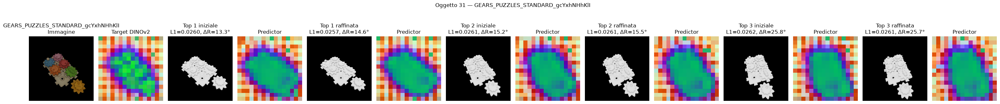

[OBJ 32] Perricone_MD_AcylGlutathione_Eye_Lid_Serum: campionate 400 pose | Best Pose (R real) L1=0.0200
[OBJ 32] Best wrt geodesic distance 30.830°, con L1=0.0291
    step 0: loss=0.027543, grad_norm=0.005582
    step 20: loss=0.027229, grad_norm=0.007128
    step 40: loss=0.027146, grad_norm=0.001851
    step 60: loss=0.026878, grad_norm=0.007011
    step 80: loss=0.026800, grad_norm=0.005614
    step 100: loss=0.026791, grad_norm=0.002646
    step 120: loss=0.026782, grad_norm=0.002404
    step 140: loss=0.026780, grad_norm=0.001701
    step 160: loss=0.026779, grad_norm=0.000612
    step 180: loss=0.026779, grad_norm=0.000303
[OBJ 32] Refine: L1 0.0275 -> 0.0268 | ΔR 51.63° -> 33.84° | step usati: 195
    step 0: loss=0.028070, grad_norm=0.003103
    step 20: loss=0.027975, grad_norm=0.007905
    step 40: loss=0.027953, grad_norm=0.006633
    step 60: loss=0.027952, grad_norm=0.003929
    step 80: loss=0.027952, grad_norm=0.004474
    step 100: loss=0.027952, grad_norm=0.002777
    

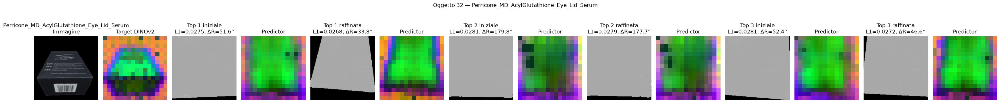

[OBJ 33] ReadytoUse_Rolled_Fondant_Pure_White_24_oz_box: campionate 400 pose | Best Pose (R real) L1=0.0244
[OBJ 33] Best wrt geodesic distance 21.909°, con L1=0.0305
    step 0: loss=0.028795, grad_norm=0.007815
    step 20: loss=0.027078, grad_norm=0.005490
    step 40: loss=0.026150, grad_norm=0.007308
    step 60: loss=0.024932, grad_norm=0.005502
    step 80: loss=0.024509, grad_norm=0.003925
    step 100: loss=0.024353, grad_norm=0.002654
    step 120: loss=0.024345, grad_norm=0.001681
    step 140: loss=0.024341, grad_norm=0.000543
    step 160: loss=0.024341, grad_norm=0.000179
    step 180: loss=0.024341, grad_norm=0.000086
[OBJ 33] Refine: L1 0.0288 -> 0.0243 | ΔR 37.47° -> 1.16° | step usati: 192
    step 0: loss=0.028912, grad_norm=0.007299
    step 20: loss=0.027323, grad_norm=0.010006
    step 40: loss=0.026156, grad_norm=0.011295
    step 60: loss=0.025513, grad_norm=0.007774
    step 80: loss=0.025359, grad_norm=0.001511
    step 100: loss=0.025353, grad_norm=0.000948
 

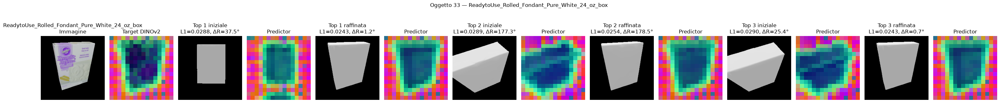

[OBJ 34] Melissa_Doug_Jumbo_Knob_Puzzles_Barnyard_Animals: campionate 400 pose | Best Pose (R real) L1=0.0261
[OBJ 34] Best wrt geodesic distance 9.675°, con L1=0.0264
    step 0: loss=0.026448, grad_norm=0.005867
    step 20: loss=0.026310, grad_norm=0.004283
    step 40: loss=0.026326, grad_norm=0.000619
    step 60: loss=0.026320, grad_norm=0.001116
    step 80: loss=0.026319, grad_norm=0.000794
    step 100: loss=0.026319, grad_norm=0.000293
    step 120: loss=0.026319, grad_norm=0.000175
    step 140: loss=0.026319, grad_norm=0.000180
[OBJ 34] Refine: L1 0.0264 -> 0.0263 | ΔR 9.68° -> 7.69° | step usati: 145
    step 0: loss=0.026735, grad_norm=0.002791
    step 20: loss=0.026516, grad_norm=0.009757
    step 40: loss=0.026324, grad_norm=0.003387
    step 60: loss=0.026367, grad_norm=0.003068
    step 80: loss=0.026146, grad_norm=0.001383
    step 100: loss=0.026112, grad_norm=0.001707
    step 120: loss=0.026096, grad_norm=0.001205
    step 140: loss=0.026095, grad_norm=0.000782
 

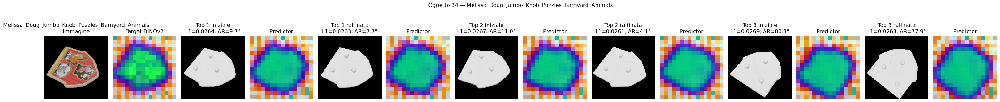

[OBJ 35] MOSAIC: campionate 400 pose | Best Pose (R real) L1=0.0218
[OBJ 35] Best wrt geodesic distance 8.010°, con L1=0.0249
    step 0: loss=0.024919, grad_norm=0.024339
    step 20: loss=0.022010, grad_norm=0.011406
    step 40: loss=0.021781, grad_norm=0.005744
    step 60: loss=0.021714, grad_norm=0.003039
    step 80: loss=0.021712, grad_norm=0.001108
    step 100: loss=0.021709, grad_norm=0.001231
    step 120: loss=0.021709, grad_norm=0.000608
    step 140: loss=0.021709, grad_norm=0.000091
[OBJ 35] Refine: L1 0.0249 -> 0.0217 | ΔR 8.01° -> 2.36° | step usati: 158
    step 0: loss=0.025053, grad_norm=0.023056
    step 20: loss=0.022013, grad_norm=0.010799
    step 40: loss=0.021801, grad_norm=0.009222
    step 60: loss=0.021714, grad_norm=0.003322
    step 80: loss=0.021708, grad_norm=0.001441
    step 100: loss=0.021705, grad_norm=0.000438
    step 120: loss=0.021705, grad_norm=0.000164
    step 140: loss=0.021705, grad_norm=0.000132
[OBJ 35] Refine: L1 0.0251 -> 0.0217 | ΔR 1

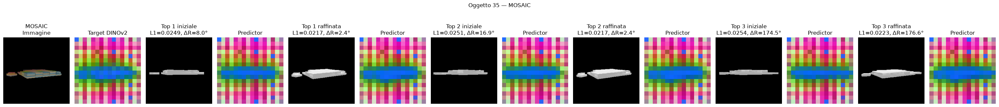

[OBJ 36] Office_Depot_Canon_PGI22_Remanufactured_Ink_Cartridge_Black: campionate 400 pose | Best Pose (R real) L1=0.0186
[OBJ 36] Best wrt geodesic distance 13.415°, con L1=0.0269
    step 0: loss=0.026824, grad_norm=0.007996
    step 20: loss=0.019966, grad_norm=0.062926
    step 40: loss=0.018423, grad_norm=0.011059
    step 60: loss=0.018422, grad_norm=0.006056
    step 80: loss=0.018404, grad_norm=0.001545
    step 100: loss=0.018398, grad_norm=0.002121
    step 120: loss=0.018398, grad_norm=0.001348
    step 140: loss=0.018398, grad_norm=0.000389
    step 160: loss=0.018398, grad_norm=0.000169
[OBJ 36] Refine: L1 0.0268 -> 0.0184 | ΔR 14.58° -> 1.85° | step usati: 161
    step 0: loss=0.026911, grad_norm=0.027017
    step 20: loss=0.020506, grad_norm=0.053037
    step 40: loss=0.018445, grad_norm=0.016665
    step 60: loss=0.018427, grad_norm=0.007222
    step 80: loss=0.018410, grad_norm=0.001908
    step 100: loss=0.018401, grad_norm=0.003261
    step 120: loss=0.018399, grad_no

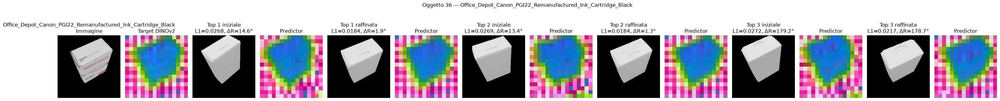

[OBJ 37] CoQ10: campionate 400 pose | Best Pose (R real) L1=0.0198
[OBJ 37] Best wrt geodesic distance 33.648°, con L1=0.0331
    step 0: loss=0.028343, grad_norm=0.017610
    step 20: loss=0.028125, grad_norm=0.004163
    step 40: loss=0.028002, grad_norm=0.005558
    step 60: loss=0.027729, grad_norm=0.011298
    step 80: loss=0.026746, grad_norm=0.005056
    step 100: loss=0.025732, grad_norm=0.010435
    step 120: loss=0.025701, grad_norm=0.003647
    step 140: loss=0.025623, grad_norm=0.003854
    step 160: loss=0.025584, grad_norm=0.005356
    step 180: loss=0.025604, grad_norm=0.008127
    step 200: loss=0.025594, grad_norm=0.003545
    step 220: loss=0.025593, grad_norm=0.000884
    step 240: loss=0.025593, grad_norm=0.000731
    step 260: loss=0.025593, grad_norm=0.000327
[OBJ 37] Refine: L1 0.0283 -> 0.0256 | ΔR 75.46° -> 33.76° | step usati: 268
    step 0: loss=0.028356, grad_norm=0.004331
    step 20: loss=0.028223, grad_norm=0.011931
    step 40: loss=0.028122, grad_norm=

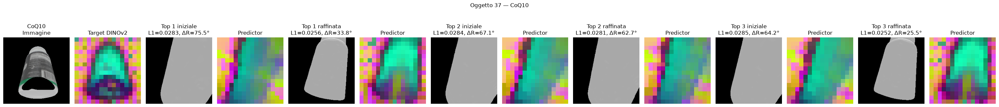

[OBJ 38] Perricone_MD_Vitamin_C_Ester_15: campionate 400 pose | Best Pose (R real) L1=0.0164
[OBJ 38] Best wrt geodesic distance 16.127°, con L1=0.0275
    step 0: loss=0.025668, grad_norm=0.015250
    step 20: loss=0.023638, grad_norm=0.031000
    step 40: loss=0.022619, grad_norm=0.034628
    step 60: loss=0.022357, grad_norm=0.016852
    step 80: loss=0.022224, grad_norm=0.036228
    step 100: loss=0.022210, grad_norm=0.013179
    step 120: loss=0.022227, grad_norm=0.006423
    step 140: loss=0.022242, grad_norm=0.038109
    step 160: loss=0.022194, grad_norm=0.020671
    step 180: loss=0.022223, grad_norm=0.011188
    step 200: loss=0.022165, grad_norm=0.006156
    step 220: loss=0.022180, grad_norm=0.020313
    step 240: loss=0.022231, grad_norm=0.019491
    step 260: loss=0.022245, grad_norm=0.006240
    step 280: loss=0.022266, grad_norm=0.010005
    step 300: loss=0.022206, grad_norm=0.017293
    step 320: loss=0.022182, grad_norm=0.032395
    step 340: loss=0.022198, grad_norm

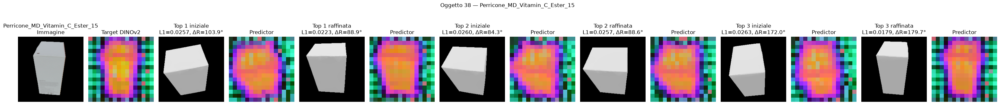

[OBJ 39] Seagate_Archive_HDD_8_TB_Internal_hard_drive_SATA_6Gbs_35_ST8000AS0002: campionate 400 pose | Best Pose (R real) L1=0.0208
[OBJ 39] Best wrt geodesic distance 34.150°, con L1=0.0318
    step 0: loss=0.026130, grad_norm=0.021392
    step 20: loss=0.025399, grad_norm=0.010408
    step 40: loss=0.025377, grad_norm=0.004226
    step 60: loss=0.025370, grad_norm=0.002310
    step 80: loss=0.025369, grad_norm=0.000737
    step 100: loss=0.025368, grad_norm=0.000386
    step 120: loss=0.025368, grad_norm=0.000181
[OBJ 39] Refine: L1 0.0261 -> 0.0254 | ΔR 39.21° -> 35.30° | step usati: 129
    step 0: loss=0.026698, grad_norm=0.021891
    step 20: loss=0.025672, grad_norm=0.004210
    step 40: loss=0.025672, grad_norm=0.006392
    step 60: loss=0.025668, grad_norm=0.005847
    step 80: loss=0.025670, grad_norm=0.006867
    step 100: loss=0.025668, grad_norm=0.004101
    step 120: loss=0.025665, grad_norm=0.004095
    step 140: loss=0.025664, grad_norm=0.003500
    step 160: loss=0.025

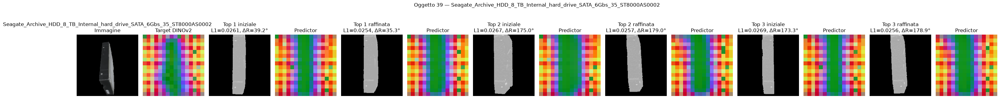

In [ ]:
from scipy.spatial.transform import Rotation
from pytorch3d.transforms import so3_exp_map

# =========================
# Utility: geometria SO(3) (numpy, per sampling deterministico)
# =========================

def geodesic_distance(R1, R2):
    R_diff = R1.T @ R2
    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))
    return np.rad2deg(angle)


def skew_np(v):
    return np.array([
        [0, -v[2], v[1]],
        [v[2], 0, -v[0]],
        [-v[1], v[0], 0]
    ])


def rotation_matrix_axis_angle_np(axis, angle):
    axis = axis / np.linalg.norm(axis)
    K_ = skew_np(axis)
    return np.eye(3) + np.sin(angle) * K_ + (1 - np.cos(angle)) * (K_ @ K_)


def rotation_from_direction_np(direction, forward=np.array([0.0, 0.0, 1.0])):
    direction = direction / np.linalg.norm(direction)
    v = np.cross(forward, direction)
    c = np.dot(forward, direction)
    s = np.linalg.norm(v)
    if s < 1e-8:
        if c > 0:
            return np.eye(3)
        orth = np.array([1.0, 0.0, 0.0]) if abs(forward[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        axis = np.cross(forward, orth)
        return rotation_matrix_axis_angle_np(axis, np.pi)
    K_ = skew_np(v)
    return np.eye(3) + K_ + K_ @ K_ * ((1 - c) / (s ** 2))


def fibonacci_sphere(n):
    points = []
    golden_angle = np.pi * (3.0 - np.sqrt(5.0))
    for i in range(n):
        y = 1 - (i / float(max(n - 1, 1))) * 2
        radius = np.sqrt(max(0.0, 1 - y * y))
        theta = golden_angle * i
        x = np.cos(theta) * radius
        z = np.sin(theta) * radius
        points.append([x, y, z])
    return np.array(points)


N_DIRS = 20
N_ROLL = 20
TOP_K = 3
REFINE_LR = 0.01          # Adam di solito tollera LR leggermente più alto del GD vanilla
LOSS_TOL = 1e-8
MAX_STEPS = 1000
PATIENCE = 15             # step consecutivi senza miglioramento prima di fermarsi
GRAD_NORM_LOG_EVERY = 20  # ogni quanti step stampare la norma del gradiente (se verbose)

directions_global = fibonacci_sphere(N_DIRS)
golden_ratio = (1 + np.sqrt(5)) / 2


def process_object(OBJ, verbose=True):
    """Esegue sampling + refine (Riemannian Adam) + plot per un singolo oggetto del batch."""

    # --- dati dell'oggetto ---
    img = batch['image'][OBJ].unsqueeze(0).to(device).float()
    mask = batch['mask'][OBJ].to(device).float()

    R_real = batch['rot_matrix'][OBJ].unsqueeze(0).to(device).float()
    t_real = batch['trans'][OBJ].unsqueeze(0).to(device).float()
    R_real_np = R_real.squeeze(0).cpu().numpy()

    centroid = batch['centroid'][OBJ].unsqueeze(0).to(device).float()
    scale = batch['scale'][OBJ].unsqueeze(0).to(device).float()

    context_t = batch['context_3d'][OBJ].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][OBJ].unsqueeze(0).to(device).float()

    K = batch['K'][OBJ].unsqueeze(0).to(device).float()

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    K_np = batch['K'][OBJ].cpu().numpy()
    t_real_np = t_real.squeeze(0).cpu().numpy()
    centroid_np = batch['centroid'][OBJ].cpu().numpy()
    scale_np = float(batch['scale'][OBJ].item())
    model_name = batch['model_name'][OBJ]

    with torch.no_grad():
        target = encoder2d(img)
        ray_dirs, moment = _generate_rays(K, R_real, t_real, centroid, scale)
        pred_real = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                               context_features=context_t, context_centers=centers_t)

    img_denorm = (img * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    L1_real = masked_l1_per_sample(pred_real, target, token_mask_t).item()

    # --- 1) sampling deterministico ---
    results = []
    with torch.no_grad():
        for direction in directions_global:
            R_dir = rotation_from_direction_np(direction)
            for ri in range(N_ROLL):
                psi = 2 * np.pi * ((ri * golden_ratio) % 1.0)
                R_roll = rotation_matrix_axis_angle_np(direction, psi)
                R = R_roll @ R_dir

                R_t = torch.from_numpy(R).unsqueeze(0).to(device).float()
                ray_dirs, moment = _generate_rays(K, R_t, t_real, centroid, scale)
                pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                  context_features=context_t, context_centers=centers_t)

                results.append({
                    'R': R,
                    'pred': pred,
                    'L1': masked_l1_per_sample(pred, target, token_mask_t).item(),
                    'diff': geodesic_distance(R_real_np, R),
                })

    if verbose:
        print(f"[OBJ {OBJ}] {model_name}: campionate {len(results)} pose "
              f"| Best Pose (R real) L1={L1_real:.4f}")

    results.sort(key=lambda x: x['L1'])
    results_by_diff = sorted(results, key=lambda x: x['diff'])
    if verbose:
        print(f"[OBJ {OBJ}] Best wrt geodesic distance {results_by_diff[0]['diff']:.3f}°, "
              f"con L1={results_by_diff[0]['L1']:.4f}")

    # --- 2) refine con Riemannian Adam (left-trivialization su SO(3)) sulle top-3 ---
    top_candidates = results[:TOP_K]
    refined_results = []

    for cand in top_candidates:
        R_current = torch.from_numpy(cand['R']).unsqueeze(0).to(device).float()

        # w resta lo stesso tensore per tutto il refine: azzerato IN PLACE ad ogni step
        # cosi' l'optimizer mantiene i suoi buffer di momento/varianza (Adam ha senso
        # perche' w vive sempre nella stessa algebra di Lie so(3)=R^3 via left-trivialization,
        # non nello spazio tangente "locale" di R_current che cambia ad ogni step)
        w = torch.zeros(1, 3, device=device, requires_grad=True)
        optimizer = torch.optim.Adam([w], lr=REFINE_LR)

        l1_history = [cand['L1']]
        prev_loss = None
        patience_counter = 0
        step_used = 0

        for step in range(MAX_STEPS):
            optimizer.zero_grad()

            R_step = so3_exp_map(w) @ R_current
            ray_dirs, moment = _generate_rays(K, R_step, t_real, centroid, scale)
            pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                              context_features=context_t, context_centers=centers_t)
            loss = masked_l1_per_sample(pred, target, token_mask_t)
            current_loss = loss.item()

            loss.backward()
            grad_norm = w.grad.norm().item()
            optimizer.step()

            # assorbi lo step nella rotazione corrente, poi resetta w a zero IN PLACE
            with torch.no_grad():
                R_current = (so3_exp_map(w) @ R_current).detach()
                w.zero_()

            step_used = step + 1

            if verbose and step % GRAD_NORM_LOG_EVERY == 0:
                print(f"    step {step}: loss={current_loss:.6f}, grad_norm={grad_norm:.6f}")

            # early stopping con pazienza, non su un singolo step
            if prev_loss is not None and (prev_loss - current_loss) < LOSS_TOL:
                patience_counter += 1
                if patience_counter >= PATIENCE:
                    break
            else:
                patience_counter = 0
            prev_loss = current_loss
            l1_history.append(current_loss)

        with torch.no_grad():
            ray_dirs, moment = _generate_rays(K, R_current, t_real, centroid, scale)
            pred_final = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                    context_features=context_t, context_centers=centers_t)
            l1_final = masked_l1_per_sample(pred_final, target, token_mask_t).item()

        R_final_np = R_current.squeeze(0).cpu().numpy()
        diff_final = geodesic_distance(R_real_np, R_final_np)

        refined_results.append({
            'R_init': cand['R'], 'L1_init': cand['L1'], 'diff_init': cand['diff'],
            'R_final': R_final_np, 'pred_final': pred_final,
            'L1_final': l1_final, 'diff_final': diff_final,
            'l1_history': l1_history,
        })

        if verbose:
            print(f"[OBJ {OBJ}] Refine: L1 {cand['L1']:.4f} -> {l1_final:.4f} "
                  f"| ΔR {cand['diff']:.2f}° -> {diff_final:.2f}° "
                  f"| step usati: {step_used}")

    # --- 3) plot per questo oggetto ---
    target_np = target.squeeze(0).cpu().numpy()
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    N_COLS = 2 + 4 * TOP_K
    fig, axes = plt.subplots(1, N_COLS, figsize=(2.2 * N_COLS, 4))

    axes[0].imshow(bg_img)
    axes[0].set_title(f"{model_name}\nImmagine")
    axes[0].axis('off')

    axes[1].imshow(target_map)
    axes[1].set_title("Target DINOv2")
    axes[1].axis('off')

    for j, res in enumerate(refined_results):
        base_col = 2 + 4 * j

        render_init = render_gso_object(
            model_name, res['R_init'], t_real_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )
        pred_init_np = top_candidates[j]['pred'].squeeze(0).cpu().numpy()
        pred_init_map = to_rgb_map_local(pca.transform(pred_init_np))

        axes[base_col].imshow(render_init)
        axes[base_col].set_title(f"Top {j+1} iniziale\nL1={res['L1_init']:.4f}, ΔR={res['diff_init']:.1f}°")
        axes[base_col].axis('off')

        axes[base_col + 1].imshow(pred_init_map)
        axes[base_col + 1].set_title("Predictor")
        axes[base_col + 1].axis('off')

        render_final = render_gso_object(
            model_name, res['R_final'], t_real_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )
        pred_final_np = res['pred_final'].detach().squeeze(0).cpu().numpy()
        pred_final_map = to_rgb_map_local(pca.transform(pred_final_np))

        axes[base_col + 2].imshow(render_final)
        axes[base_col + 2].set_title(f"Top {j+1} raffinata\nL1={res['L1_final']:.4f}, ΔR={res['diff_final']:.1f}°")
        axes[base_col + 2].axis('off')

        axes[base_col + 3].imshow(pred_final_map)
        axes[base_col + 3].set_title("Predictor")
        axes[base_col + 3].axis('off')

    plt.suptitle(f"Oggetto {OBJ} — {model_name}")
    plt.tight_layout()
    plt.show()

    return {
        'OBJ': OBJ,
        'model_name': model_name,
        'L1_real': L1_real,
        'results_sorted': results,
        'refined_results': refined_results,
    }


# =========================
# Esegui su tutti gli oggetti del batch
# =========================
all_objects_results = []
for OBJ in range(BATCH_SIZE):
    res = process_object(OBJ)
    all_objects_results.append(res)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from pytorch3d.transforms import so3_exp_map
from mpl_toolkits.mplot3d import Axes3D  # noqa: necessario per projection='3d'


def random_tangent_basis(seed=None):
    """Due vettori tangenti ortonormali random nell'algebra di Lie so(3) (R^3). USATI PER PLOTTARE IL MANIFOLD """
    rng = np.random.default_rng(seed)
    v1 = rng.normal(size=3)
    v1 /= np.linalg.norm(v1)
    v2 = rng.normal(size=3)
    v2 -= np.dot(v2, v1) * v1           # Tolgo la proiezione di v2 su v1 per renderli ortogonali
    v2 /= np.linalg.norm(v2)
    return v1, v2


def compute_loss_manifold(OBJ, R_center_np, v1, v2, extent_deg=180, n_grid=41, verbose=True):
    """
    Calcola la L1 
    """
    img = batch['image'][OBJ].unsqueeze(0).to(device).float()
    mask = batch['mask'][OBJ].to(device).float()
    t_real = batch['trans'][OBJ].unsqueeze(0).to(device).float()
    centroid = batch['centroid'][OBJ].unsqueeze(0).to(device).float()
    scale = batch['scale'][OBJ].unsqueeze(0).to(device).float()
    context_t = batch['context_3d'][OBJ].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][OBJ].unsqueeze(0).to(device).float()
    K = batch['K'][OBJ].unsqueeze(0).to(device).float()

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    with torch.no_grad():
        target = encoder2d(img)

    extent_rad = np.deg2rad(extent_deg)
    alphas = np.linspace(-extent_rad, extent_rad, n_grid)
    betas = np.linspace(-extent_rad, extent_rad, n_grid)
    AA, BB = np.meshgrid(alphas, betas)

    R_center_t = torch.from_numpy(R_center_np).unsqueeze(0).to(device).float()
    loss_grid = np.zeros((n_grid, n_grid), dtype=np.float32)

    with torch.no_grad():
        for i in range(n_grid):
            for j in range(n_grid):
                w = (AA[i, j] * v1 + BB[i, j] * v2).astype(np.float32)
                w_t = torch.from_numpy(w).unsqueeze(0).to(device)
                R_ij = so3_exp_map(w_t) @ R_center_t
                ray_dirs, moment = _generate_rays(K, R_ij, t_real, centroid, scale)
                pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                  context_features=context_t, context_centers=centers_t)
                loss_grid[i, j] = masked_l1_per_sample(pred, target, token_mask_t).item()
        if verbose:
            print(f"Griglia {n_grid}x{n_grid} completata ({n_grid*n_grid} forward pass), "
                  f"L1 range=[{loss_grid.min():.4f}, {loss_grid.max():.4f}]")

    return AA, BB, loss_grid  # radianti


import plotly.graph_objects as go


def plot_loss_manifold(OBJ, model_name, AA, BB, loss_grid, center_label="R_real"):
    AA_deg = np.rad2deg(AA)
    BB_deg = np.rad2deg(BB)
    center_i, center_j = loss_grid.shape[0] // 2, loss_grid.shape[1] // 2
    center_z = loss_grid[center_i, center_j]

    fig = go.Figure()

    # --- superficie 3D interattiva ---
    fig.add_trace(
        go.Surface(
            x=AA_deg, y=BB_deg, z=loss_grid,
            colorscale='Viridis',
            colorbar=dict(title="L1 loss"),
            showscale=True,
            name="loss"
        )
    )
    fig.add_trace(
        go.Scatter3d(
            x=[0], y=[0], z=[center_z],
            mode='markers',
            marker=dict(size=6, color='red'),
            name=center_label
        )
    )

    fig.update_scenes(
        xaxis_title='α (°) — direzione v1',
        yaxis_title='β (°) — direzione v2',
        zaxis_title='L1 loss'
    )

    fig.update_layout(
        height=700, width=900,
        title_text=f"Manifold L1 — OBJ {OBJ} ({model_name})<br>piano tangente attorno a {center_label}",
        legend=dict(x=0.75, y=0.9)
    )

    fig.show()


# =========================
# ESEGUI: confronta un oggetto che funziona bene con uno che fallisce
# =========================
EXTENT_DEG = 180   # ampiezza del piano tangente, ± gradi
N_GRID = 41       # risoluzione (41x41 = 1681 forward pass per slice, ~1-2 min su GPU)

allobj = [(i, 0) for i in range(40)]
for OBJ_TO_TEST, seed in allobj:   # 27 = donut (buono), 39 = fire engine (fallisce)
    R_real_np = batch['rot_matrix'][OBJ_TO_TEST].cpu().numpy()
    model_name = batch['model_name'][OBJ_TO_TEST]

    v1, v2 = random_tangent_basis(seed=seed)
    AA, BB, loss_grid = compute_loss_manifold(OBJ_TO_TEST, R_real_np, v1, v2,
                                               extent_deg=EXTENT_DEG, n_grid=N_GRID)
    plot_loss_manifold(OBJ_TO_TEST, model_name, AA, BB, loss_grid, center_label="R_real")

Griglia 41x41 completata (1681 forward pass), L1 range=[0.0251, 0.0374]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0222, 0.0366]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0215, 0.0358]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0233, 0.0357]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0228, 0.0370]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0240, 0.0362]


... (30 outputs left out)

Griglia 41x41 completata (1681 forward pass), L1 range=[0.0186, 0.0360]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0197, 0.0364]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0164, 0.0352]


Griglia 41x41 completata (1681 forward pass), L1 range=[0.0208, 0.0361]


# BOP OBJECT


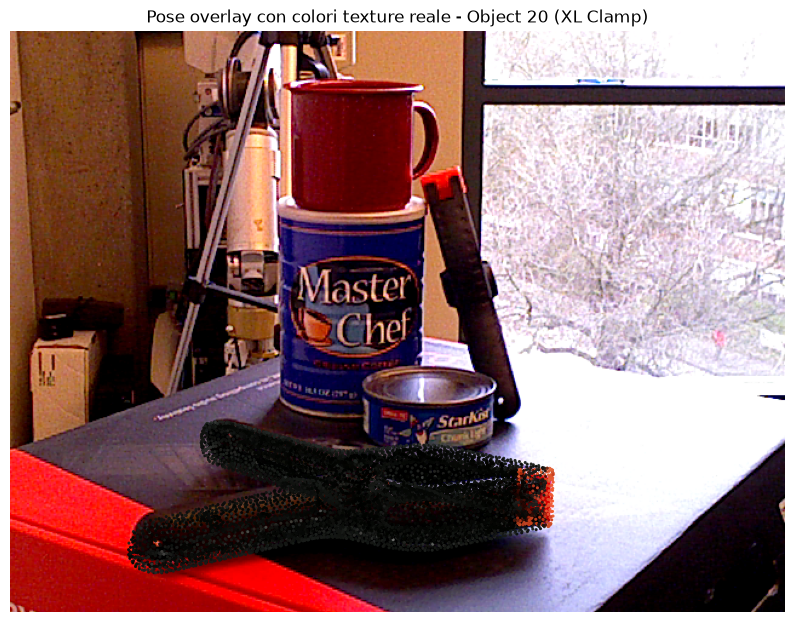

In [ ]:
# CHOOSE A SINGLE IMAGE. IN THIS CASE FROM THE DATASET YCBV (Scene 48, Image 47, Object 20 - XL Clamp)

import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

rgb_path = "/data/riccardop02/datasets/ycbv/test/000048/rgb/000047.png"
mask_path = "/data/riccardop02/datasets/ycbv/test/000048/mask_visib/000001_000004.png"
scene_camera_path = "/data/riccardop02/datasets/ycbv/test/000048/scene_camera.json"
model_path = "/data/riccardop02/datasets/ycbv/models/obj_000020.ply"


Pose = {
    "cam_R_m2c": [-0.9993032187000758, -0.03468586763469483, 0.013799769394337228,
                   0.02273746658654025, -0.27237133848523803, 0.9619233928797483,
                  -0.02960648331060263, 0.9615662504172701, 0.2729703664836574],
    "cam_t_m2c": [-20.983454465364908, 85.55142809136696, 684.4252367092936]
}

# --- Intrinseci ---
with open(scene_camera_path, "r") as f:
    scene_camera = json.load(f)
K = np.array(scene_camera["47"]["cam_K"]).reshape(3, 3)

# --- Carica mesh (texture già embedded automaticamente da trimesh) ---
mesh = trimesh.load(model_path, process=False)
vertices = np.array(mesh.vertices)               # (10064, 3)
uv = np.array(mesh.visual.uv)                     # (10064, 2)

# --- Usa la texture già caricata da trimesh, non ricaricarla da file ---
texture_img = np.array(mesh.visual.material.image.convert("RGB"))  # (4096, 4096, 3)
tex_h, tex_w = texture_img.shape[:2]

# --- Converti UV in coordinate pixel della texture ---
u_px = np.clip((uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
v_px = np.clip(((1 - uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)  # flip verticale

vertex_colors = texture_img[v_px, u_px] / 255.0   # (10064, 3), in [0,1]

# --- Trasforma i vertici in camera coords e proietta ---
R = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t = np.array(Pose["cam_t_m2c"]).reshape(3, 1)

points_cam = (R @ vertices.T) + t
points_img_h = K @ points_cam
points_img = (points_img_h[:2, :] / points_img_h[2, :]).T

# --- Carica RGB della scena ---
rgb = cv2.imread(rgb_path)
rgb_rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

valid = (points_img[:, 0] >= 0) & (points_img[:, 0] < w) & \
        (points_img[:, 1] >= 0) & (points_img[:, 1] < h)

# --- Plot con i colori reali della texture ---
plt.figure(figsize=(10, 8))
plt.imshow(rgb_rgb)
plt.scatter(points_img[valid, 0], points_img[valid, 1],
            s=1.5, c=vertex_colors[valid], alpha=0.9)
plt.title("Pose overlay con colori texture reale - Object 20 (XL Clamp)")
plt.axis('off')
plt.show()

In [ ]:
def load_ycbv_mesh(model_path: str) -> trimesh.Trimesh:
    """Equivalente di load_gso_mesh, ma per un singolo file .ply YCB-V con texture embedded."""
    mesh = trimesh.load(model_path, process=False)
    if not isinstance(mesh, trimesh.Trimesh):
        raise ValueError(f"Expected a single mesh, got {type(mesh)}")
    return mesh


def process_single_object(model_path: str, encoder3d, n_points: int, device: torch.device):
    """Versione single-object di process_model, per test rapido su Object 20."""
    mesh = load_ycbv_mesh(model_path)
    pc = sample_pointcloud_with_color(mesh, n_points)
    pc, centroid, scale = normalize_pointcloud(pc)

    pc_tensor = torch.from_numpy(pc).unsqueeze(0).to(device)  # (1, N, 6)

    with torch.no_grad():
        feats, centers = encoder3d.extractFeatures(pc_tensor)

    return feats.squeeze(0).cpu().numpy(), centers.squeeze(0).cpu().numpy(), centroid.squeeze(), scale


Object 20 (XL Clamp): L1 pred=0.0302 | L1 pred(+5°)=0.0303


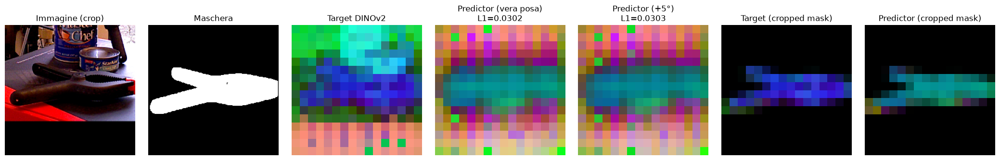

In [ ]:
# =========================
# Visualizzazione: BOP (YCB-V) - target vs predictor, vera posa vs posa sbagliata
# =========================
from sklearn.decomposition import PCA

IMG_SIZE = 224          # deve combaciare con quello usato in training/encoder2d
CROP_MARGIN = 1.02       # margine attorno al bbox della maschera (1.0 = bbox esatto)
WRONG_ROT_DEG = 5.0
ROT_AXIS = 'y'

# --- Carica immagine e maschera ---
mask_full = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
rgb_full = cv2.cvtColor(cv2.imread(rgb_path), cv2.COLOR_BGR2RGB)
h, w = rgb_full.shape[:2]

# --- Bbox della maschera + margine, crop quadrato ---
ys, xs = np.where(mask_full > 0)
x0, x1 = xs.min(), xs.max()
y0, y1 = ys.min(), ys.max()
cx_box, cy_box = (x0 + x1) / 2, (y0 + y1) / 2
side = max(x1 - x0, y1 - y0) * CROP_MARGIN

x0c, x1c = int(cx_box - side / 2), int(cx_box + side / 2)
y0c, y1c = int(cy_box - side / 2), int(cy_box + side / 2)

# --- Crop (con padding se esce dai bordi immagine) ---
pad_l, pad_t = max(0, -x0c), max(0, -y0c)
pad_r, pad_b = max(0, x1c - w), max(0, y1c - h)
x0c, y0c = max(0, x0c), max(0, y0c)
x1c, y1c = min(w, x1c), min(h, y1c)

rgb_crop = rgb_full[y0c:y1c, x0c:x1c]
mask_crop = mask_full[y0c:y1c, x0c:x1c]
if any([pad_l, pad_t, pad_r, pad_b]):
    rgb_crop = cv2.copyMakeBorder(rgb_crop, pad_t, pad_b, pad_l, pad_r, cv2.BORDER_CONSTANT, value=0)
    mask_crop = cv2.copyMakeBorder(mask_crop, pad_t, pad_b, pad_l, pad_r, cv2.BORDER_CONSTANT, value=0)

crop_side = rgb_crop.shape[0]  # quadrato

# --- Resize a IMG_SIZE ---
rgb_resized = cv2.resize(rgb_crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
mask_resized = cv2.resize(mask_crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

# --- K aggiornata per il crop + resize (crop shift + scale) ---
K_crop = K.copy()
K_crop[0, 2] -= (x0c - pad_l)   
K_crop[1, 2] -= (y0c - pad_t)  
scale_factor = IMG_SIZE / crop_side
K_crop = K_crop * np.array([[scale_factor, 0, scale_factor],
                             [0, scale_factor, scale_factor],
                             [0, 0, 1]])
K_crop[2, 2] = 1.0

# --- Tensor immagine, normalizzata come si aspetta encoder2d ---
img_np = rgb_resized.astype(np.float32) / 255.0
img_t_raw = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device).float()
img_t = (img_t_raw - MEAN_t) / STD_t

K_t = torch.from_numpy(K_crop).unsqueeze(0).to(device).float()

# --- Posa vera dalla annotazione BOP ---
R_true = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t_true = np.array(Pose["cam_t_m2c"]).reshape(3)
rot_t = torch.from_numpy(R_true).unsqueeze(0).to(device).float()
trans_t = torch.from_numpy(t_true).unsqueeze(0).to(device).float()

# --- centroid/scale/context 3D dal CAD model (Cell 2) ---
feats3d, centers, centroid, scale = process_single_object(model_path, encoder3d, n_points=8192, device=device)
context_t = torch.from_numpy(feats3d).unsqueeze(0).to(device).float()
centers_t = torch.from_numpy(centers).unsqueeze(0).to(device).float()
centroid_t = torch.from_numpy(centroid).unsqueeze(0).to(device).float()
scale_t = torch.tensor([scale], device=device).float()

# --- posa "sbagliata" ---
R_offset = rotation_matrix(ROT_AXIS, WRONG_ROT_DEG, device)
rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

# --- maschera a livello di token ---
mask_bin = (mask_resized > 0).astype(np.float32)
token_mask_np = pixel_mask_to_token_mask(mask_bin, grid_size=GRID_SIZE)
token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

with torch.no_grad():
    target = encoder2d(img_t)
    pred = predictor(ray_dirs=ray_dirs, ray_moments=moment_c,
                      context_features=context_t, context_centers=centers_t)
    pred_wrong = predictor(ray_dirs=ray_dirs_wrong, ray_moments=moment_wrong,
                            context_features=context_t, context_centers=centers_t)

    l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
    l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()

target_np = target.squeeze(0).cpu().numpy()
pred_np = pred.squeeze(0).cpu().numpy()
pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()

pca = PCA(n_components=3)
target_pca = pca.fit_transform(target_np)
pred_pca = pca.transform(pred_np)
pred_wrong_pca = pca.transform(pred_wrong_np)

target_map = to_rgb_map_local(target_pca)
pred_map = to_rgb_map_local(pred_pca)
pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

print(f"Object 20 (XL Clamp): L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_wrong:.4f}" if False else
      f"Object 20 (XL Clamp): L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_pred_wrong:.4f}")

fig, axes = plt.subplots(1, 7, figsize=(21, 3.2))
axes[0].imshow(rgb_resized); axes[0].set_title("Immagine (crop)"); axes[0].axis('off')
axes[1].imshow(mask_resized, cmap='gray'); axes[1].set_title("Maschera"); axes[1].axis('off')
axes[2].imshow(target_map); axes[2].set_title("Target DINOv2"); axes[2].axis('off')
axes[3].imshow(pred_map); axes[3].set_title(f"Predictor (vera posa)\nL1={l1_pred:.4f}"); axes[3].axis('off')
axes[4].imshow(pred_wrong_map); axes[4].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}°)\nL1={l1_pred_wrong:.4f}"); axes[4].axis('off')
axes[5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[5].set_title("Target (cropped mask)"); axes[5].axis('off')
axes[6].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[6].set_title("Predictor (cropped mask)"); axes[6].axis('off')

plt.tight_layout()
plt.show()